# [2.5] - MCTS & AlphaZero (exercises)

> **ARENA [Streamlit Page](https://arena-chapter2-rl.streamlit.app/05_[2.5]_MCTS_&_AlphaZero)**
>
> **Colab: [exercises](https://colab.research.google.com/github/ARENA-education/ARENA_materials/blob/main/chapter2_rl/exercises/part5_mcts_alphazero/2.5_MCTS_&_AlphaZero_exercises.ipynb?t=20261019) | [solutions](https://colab.research.google.com/github/ARENA-education/ARENA_materials/blob/main/chapter2_rl/exercises/part5_mcts_alphazero/2.5_MCTS_&_AlphaZero_solutions.ipynb?t=20261019)**

Please send any problems / bugs on the `#errata` channel in the [Slack group](https://info-arena.github.io/ARENA_img/slack.html), and ask any questions on the dedicated channels for this chapter of material.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

Links to all other chapters: [(0) Fundamentals](https://arena-chapter0-fundamentals.streamlit.app/), [(1) Transformer Interpretability](https://arena-chapter1-transformer-interp.streamlit.app/), [(2) RL](https://arena-chapter2-rl.streamlit.app/).

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-25.png" width="350">

# Introduction

Up until now we've been dealing primarily with *model-free* methods: those
that have no explicit model of how the world works, and need to learn the rules
of the game from experience. This is wasteful when the environment is already
known and cheap to simulate (like a board game). 
Today we introduce **Monte Carlo Tree Search (MCTS)**,
a *model-based* method where we have access to a simulator of the environment
that we can use for planning, and combine this with deep learning to create an agent
to play a strong game of Connect 4, learning only from self-play. This was the
same method used by AlphaGo Zero to become superhuman at Go.

The main idea is as follows:

* We use a neural network to guide the tree search.
* We select actions based on which nodes were the most visited during the tree search.
* We train the policy network to mimic the tree search, distilling the planning
into the policy network. 

This feedback loop (policy iteration via search) is what took AlphaZero from
random play to superhuman in hours.

The rough steps for today:

1. Build the **network** (a small ResNet with two heads),
2. Build a simple **single-game MCTS** in pure Python to understand the algorithm,
3. Vectorize the MCTS to run hundreds of games at once on the GPU,
4. Build the **self-play sampler** that turns search into training data, and
5. Train the network to mimic the tree search.

We've provided a vectorized implementation of Connect 4 in `part5_mcts_alphazero/game.py`, as well as a fast,
net-independent evaluation built on [Pascal Pons' perfect Connect-4 solver](https://github.com/PascalPons/connect4)
— we score the agent on how often it picks a provably optimal move. At the end, you'll have a model that trains
to a strong level in under five minutes on a GPU.

Attributions: Part of the codebase was built upon implementations of AlphaZero by

* [Surag Nair](https://github.com/suragnair/alpha-zero-general) - MIT License 
* [DeepMind](https://github.com/google-deepmind/mctx) - Apache 2.0 License

## Content & Learning Objectives

### 0️⃣ MCTS & AlphaZero — Theory

A non-exercise section introducing Monte Carlo Tree Search and how AlphaZero turns it into a
learning algorithm.

> ##### Learning Objectives
>
> - Understand the four phases of MCTS (selection, expansion, simulation, backup).
> - See how AlphaZero replaces random rollouts with a value net and uses the policy as a prior via PUCT.
> - Understand the self-play loop and loss function for the network.

### 1️⃣ The Environment & Network

We meet the provided Connect-4 environment and build the policy-value network.
The network is a small ResNet with two heads: an **actor** (policy) and a **critic** (value).

> ##### Learning Objectives
>
> - Use the provided vectorised Connect-4 environment, and understand how the board is encoded.
> - Build the AlphaZero policy-value network.

### 2️⃣ Single-Game MCTS

Implement MCTS with an explicit tree, on a single board, in pure Python.
No prizes for speed here, but it helps to write the sequential version first.

> ##### Learning Objectives
>
> - Implement a `Node` class, PUCT selection, expansion, and backup.
> - Assemble the full search loop and verify it finds tactical wins and blocks.

### 3️⃣ Simulating Vectorized MCTS

Understand the demands of the vectorized version, and explain how we can batch
the forward passes of the network using our sequential version as a reference.

> ##### Learning Objectives
>
> - Understand how we can restructure the sequential version to batch the `evaluate` stage
> of the MCTS algorithm.
> - Understand both Root Parallelization and Tree Parallelization, how they work, and
> why Root Parallelization is suited for implementing in PyTorch.
> - Build a simulated version of Root Parallelization that uses the sequential version as the backend.

### 4️⃣ Self-Play & Training

Close the loop: turn search into training data and train an agent.

> ##### Learning Objectives
>
> - Implement the self-play sampler: the tree policy, the network policy, and using the critic to estimate the value of rollouts.
> - Understand the loss function for the network and how it distills the planning provided by the tree search.
> - Train an agent to match a perfect solver's moves (and hopefully beat you too!)

### ☆ Bonus - Vectorized MCTS

Implement the vectorized version of the MCTS algorithm.
> ##### Learning Objectives
>
> - Understand how we can store trees as tensors in a way that tree search can
be performed as parallel operations on the GPU in lock-step.
> - Parallelize the selection, expansion and backup stages of the MCTS algorithm.


### ☆ Bonus

Various other extensions to MCTS, or things to try, including
data augmentation to abuse board symmetries, measuring the Elo of the model as a function of MCTS simulations, and various potential things to explore.

## Readings

- Silver et al. (2017), [*Mastering the game of Go without human knowledge*](https://www.nature.com/articles/nature24270) (AlphaGo Zero).
- Silver et al. (2018), [*A general reinforcement learning algorithm that masters chess, shogi and Go through self-play*](https://www.science.org/doi/10.1126/science.aar6404) (AlphaZero).
- Surag Nair, [*A Simple Alpha(Go) Zero Tutorial*](https://suragnair.github.io/posts/alphazero.html)
- Browne et al. (2012), [*A Survey of Monte Carlo Tree Search Methods*](https://ieeexplore.ieee.org/document/6145622) (UCB / PUCT background).

## Setup code

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

chapter = "chapter2_rl"
repo = "ARENA_materials"
branch = "main"

# Install dependencies (Colab already has torch, einops, numpy, matplotlib, plotly, tqdm and huggingface_hub)
try:
    import eindex, jaxtyping, torchinfo
except:
    %pip install einops jaxtyping torchinfo git+https://github.com/ARENA-education/eindex.git

# Get root directory, handling 3 different cases: (1) Colab, (2) notebook not in ARENA repo, (3) notebook in ARENA repo
root = (
    "/content"
    if IN_COLAB
    else "/root"
    if repo not in os.getcwd()
    else str(next(p for p in Path.cwd().parents if p.name == repo))
)

if Path(root).exists() and not Path(f"{root}/{chapter}").exists():
    if not IN_COLAB:
        !sudo apt-get install unzip
        %pip install jupyter ipython --upgrade

    if not os.path.exists(f"{root}/{chapter}"):
        !wget -P {root} https://github.com/ARENA-education/ARENA_materials/archive/refs/heads/{branch}.zip
        !unzip {root}/{branch}.zip '{repo}-{branch}/{chapter}/exercises/*' -d {root}
        !mv {root}/{repo}-{branch}/{chapter} {root}/{chapter}
        !rm {root}/{branch}.zip
        !rmdir {root}/{repo}-{branch}


if f"{root}/{chapter}/exercises" not in sys.path:
    sys.path.append(f"{root}/{chapter}/exercises")

os.chdir(f"{root}/{chapter}/exercises")

In [2]:
try:
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
except Exception:
    pass
import einops
from eindex import eindex
import math
import sys
from pathlib import Path
from dataclasses import dataclass, field, asdict
from jaxtyping import Float, Bool, Int
from torch import Tensor
import torch as t  
import torch.nn as nn
import torch.nn.functional as F
from torchinfo import summary
from tqdm.auto import tqdm

# Make sure exercises are in the path
chapter = "chapter2_rl"
section = "part5_mcts_alphazero"
exercises_dir = next(p for p in Path.cwd().parents if (p / chapter).exists()) / chapter / "exercises"
section_dir = exercises_dir / section
for _p in (str(section_dir), str(exercises_dir)):   # section_dir for bare imports; exercises_dir so
    if _p not in sys.path:                          # `from part5_mcts_alphazero.solutions import ...` resolves
        sys.path.append(_p)
import part5_mcts_alphazero.tests as tests
import part5_mcts_alphazero.utils as utils
from part5_mcts_alphazero.utils import (
    Board, Connect4Env, MCTSConfig, legal_mask_from_obs, fmt_si,
    render_board, place_piece, plot_board_and_policy, print_mcts_tree, plot_mcts_tree,
    two_ply_positions, greedy_policy_action,
)

# The single-game MCTS runs lots of tiny CPU tensor ops in a Python loop. With PyTorch's default of one
# thread per core, its threads spend longer coordinating than computing, and on cloud machines with a
# CPU quota they can get the whole process throttled (we measured a ~40x slowdown). Adjust if needed.
t.set_num_threads(min(4, t.get_num_threads()))
t.set_float32_matmul_precision('high')   # allow TF32 matmuls on Ampere+ GPUs: faster training, ~1e-3 relative precision

device = t.device("cuda" if t.cuda.is_available() else "mps" if t.backends.mps.is_available() else "cpu")
MAIN = __name__ == "__main__"
SLOW = False   # set True to run the slow bonus demos (strength-vs-sims, Elo-vs-search budget)
TRAINING = True    # set False to skip section 4 self-play training (e.g. while iterating on section 2/section 3)

# 0️⃣ MCTS & AlphaZero — Theory

> ##### Learning Objectives
>
> - Understand the four phases of MCTS (selection, expansion, simulation, backup).
> - See how AlphaZero replaces random rollouts with a value net and uses the policy as a prior via PUCT.
> - Understand the self-play loop and loss function for the network.

Connect 4 is a two-player, perfect-information, zero-sum game on a 6×7 grid. 
Our goal is an agent that *learns* strong play from self-play alone.
It is a strongly *solved* game: the optimal move is known from any board position, 
while still being a challenging game to play optimally. This is useful as we
have ground truth values with which our agent can be measured against.

## Vanilla MCTS

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/f5e39cc23d5ef4c7cffbe006f29d24a7cc745f44/img/ch25-mcts.png" width="640">

Each node stores visit counts $N$, value sums $W$, and pointers to its children.
The nodes represent **states of the game**, and the edges represent **actions** taken to transition between states.

Monte Carlo Tree Search builds a search tree rooted at the current position by repeating four
phases, many times:

1. **Selection.** Starting at the root, repeatedly pick a child according to a *tree policy*
   that balances exploiting good moves and exploring uncertain ones, until you reach a leaf node.
2. **Expansion.** Add a new child to the leaf node.
3. **Simulation (rollout).** From the new node, simulate both players with *random* moves until the end of the game and observe who won.
4. **Backup.** Propagate the result back up the path, incrementing visit counts $N$ and value sums $W$ at every node on the way.


After iterating, the **most-visited move at the root** is the actual action
the agent chooses to play.

## From MCTS to AlphaZero

AlphaZero keeps the tree-search skeleton but makes two changes.
First, we define a neural network $f_\theta$ with parameters $\theta$, mapping a state $s \in \mathcal{S}$ to a pair $(\mathbf{p}, v)$:

$$
f_\theta : \mathcal{S} \to \Delta(\mathcal{A}) \times [-1, 1]
$$

- The **policy** $\mathbf{p}(\cdot | s) \in \Delta(\mathcal{A})$ is a probability distribution over actions — $\Delta(\mathcal{A})$ denotes the set of all probability distributions over the action set $\mathcal{A}$, i.e. for Connect 4 a vector of 7 non-negative numbers summing to 1. It acts as a *prior* over which moves look promising, before any search is done.
- The **value** $v(s) \in [-1, 1]$ is an estimate of the game's eventual outcome, from the perspective of the player about to move ($-1$ = certain loss, $+1$ = certain win).

With this network, the changes to MCTS are:

1. **No random rollouts.** From leaf node $s$, we directly query the critic head $v(s)$ to get an estimate of the game's outcome (or if the game has ended,
the ground-truth reward $z \in \{-1, 0, +1\}$ for loss/draw/win respectively).


2. **A policy prior in selection.** We use **PUCT** (Predictor + Upper Confidence Trees), which biases exploration
   toward moves the policy likes:
$$
PUCT(s,a) = \underbrace{Q(s, a)}_{\text{exploitation}} + \underbrace{c \cdot p_\theta(a|s) \cdot \frac{\sqrt{1 + \sum_{a'} N(s,a')}}{1 + N(s, a)}}_{\text{exploration}}
$$

   The terms are statistics stored on the tree's edges and updated during backup:

   - $N(s, a)$ is the **visit count**: how many simulations have taken action $a$ from state $s$ so far. Summing over the actions, $N(s) := \sum_{a'} N(s,a')$, gives the total number of visits to $s$ itself.
   - $W(s, a)$ is the **total value**: the sum of all backed-up outcomes (value estimates $v$, or terminal rewards $z$) from simulations that took action $a$ from state $s$, always **from the perspective of the player to move at $s$**. The players alternate, so backup negates the value once per level on the way up: a result that is good for $s$'s mover is bad for its parent's mover.
   - $Q(s, a) := W(s,a) / \max(1, N(s,a))$ is the **mean value**: the empirical average outcome of taking $a$ from $s$. This is the *exploitation* term — it is high for moves that have done well in the search so far.
   - $p_\theta(a|s)$ is the policy head's **prior** probability for action $a$ in state $s$, before any search.
   - $c$ is a hyperparameter trading off exploitation ($Q$) against exploration (the prior-weighted second term).

   The exploration term is large when $a$ has a high prior but few visits relative to its siblings, and it shrinks as $N(s,a)$ grows — so the search initially follows the policy's suggestions, then increasingly trusts the values it has actually measured.


Why $\sqrt{1 + \sum_{a'} N(s,a')}$ rather than $\sqrt{\sum_{a'} N(s,a')}$? 

> It matters only on a node's
> <b>first visit</b>, when every $N(s,a') = 0$. Then $Q = 0$ and, with a bare $\sqrt{\sum N} = 0$,
> <b>every</b> legal action scores $0$ — so `argmax` just picks the first legal column and ignores
> the policy. The $+1$ makes $PUCT(s,a) \propto p_\theta(a|s)$ on that first visit, so the search follows the
> prior straight away, which can help if doing very few MCTS iterations. Doesn't make much of a difference for large
> numbers of simulations.

Why $z$ for reward?
> Dunno. That was the notation used in the original AlphaZero paper.

### Interactive: watch MCTS think

Here's a small **interactive visualiser** (standalone JavaScript, runs in your browser). Set up a
Connect-4 position, run the search, then you can step through the simulations to watch the tree grow
node-by-node, with each node's visit count $N$, mean value $Q$ and prior $P$. This is the
four-phase MCTS loop (select → expand → simulate → back-up) which is run once per simulation.

<a href="https://info-arena.github.io/ARENA_img/misc/media-25/mcts_visualizer.html" target="_blank" rel="noopener" style="display:inline-block; padding:10px 18px; background:#2a9d8f; color:#fff; font-weight:600; text-decoration:none; border-radius:8px;">▶ Open the interactive MCTS visualiser (new tab)</a>
   
## The self-play training loop

Each move of a self-play game:

0. Generate a node representing the current position of the game, and run the network to obtain an estimate $v(s)$ of the game's
outcome, as well as a prior $p_\theta(\cdot|s)$ for the actions to take from this position. 
- Optionally, for the root node only, we inject [Dirichlet noise](https://en.wikipedia.org/wiki/Dirichlet_distribution) into the prior to encourage exploration.

1. Run several simulations of MCTS from the current position:
    - **Selection**: Starting at the root, walk down the tree following the PUCT selection policy.
    $$
    \pi^\text{PUCT}(s) = \arg\max_{a} PUCT(s, a)
    $$
    until you run out of nodes to explore (or the node is terminal because the game ended).
    - **Expansion**: If the node is not terminal, add a new child node to the leaf node.
    - **Evaluation**: If the node is not terminal, evaluate the new child node using the critic network $v(s)$ to get an estimate of the game's outcome (or, if the child is terminal, the ground-truth reward $z \in \{-1, 0, +1\}$ for loss/draw/win respectively).
    - **Backup**: Propagate the result back up the path, incrementing visit counts $N$ and value sums $W$ at every node on the way.
    
2. The normalised visit counts 
    $$
    \pi(a | s) := \frac{N(s, a)^{1/\tau}}{\sum_{a'} N(s, a')^{1/\tau}}
    $$
    are the **target policy**: a policy improved by tree search that should give better moves than the raw policy network $p_\theta$.
    
3. Sample the actual move from $\pi$ (with temperature $\tau$ for exploration). During training, $\tau = 1$ to encourage exploration ($\pi(a|s) \propto N(s,a)$) and during evaluation, we send $\tau \to 0$, which causes $\pi$ to sample the action $a$ with the highest visit count $N(s,a)$
    $$
    \pi(a|s)\big|_{\tau \to 0} = \begin{cases}
    1 & \text{if } a = \arg\max_{a'} N(s, a') \\
    0 & \text{otherwise}
    \end{cases}
    $$
4. We train the network to try and predict the target policy, and we train the critic to predict the value of the position.
$$
\mathcal{L}(\theta) = \mathbb{E}_{s,z,\pi \sim \mathcal{D}} \left[ (z - v(s))^2 - \sum_{a} \pi(a|s) \log p_\theta(a|s) \right] 
+ c ||\theta||^2
$$
where 

 * $z$ is the ground truth reward based on the outcome of a game (win = 1, draw = 0, loss = -1),
 * $s$ are the states of the game visited during rollouts, and
 * $\pi(\cdot | s)$ are the tree policies for those states
 
 So, what is the data distribution $\mathcal{D}$ that we are sampling from? 
 It is the distribution of states, rewards, and tree policies obtained from rollouts from self-play (the network plays games against itself).
 
What about the terms in the loss function?

* The term $(z - v(s))^2$ trains the critic $v$ to try and predict the ground truth reward $z$ for the position $s$.
* The term $-\sum_{a} \pi(a|s) \log p_\theta(a|s)$ is standard cross-entropy loss to try and train the network $p_\theta$ to act like the tree policy $\pi$. The tree policy uses the network + planning via the MCTS tree, so we expect $\pi$ to be stronger than $p_\theta$. By training the network to act like the tree policy, we are trying to *distill* the planning process into the network itself 
(which in turn gives a stronger tree policy, and so on).
* The term $c ||\theta||^2$ is just a standard regularization term to prevent the network from overfitting. In practice,
I found the network trains just fine without it, but it's included here for completeness as it was present in the original AlphaZero paper.

You'll note that this is a very strange loss function for RL, and is wholly unlike policy gradient methods. This can almost be seen
as a kind of **distillation loss** where we are trying to teach $p_\theta$, the student model, to act like $\pi$, the teacher model,
except the teacher itself is bootstrapped from the student itself, plus the performance boost given by MCTS. We will see an example later on of how, even with a randomly initialized $p_\theta$, $\pi$ is still notably stronger, giving $p_\theta$ something to latch onto and 
improve itself.

# 1️⃣ The Environment & Network

> ##### Learning Objectives
>
> - Use the provided vectorised Connect-4 environment, and understand how the board is encoded.
> - Build the AlphaZero policy-value network.

> ⚠️ **Note:** The exercises in this section are pretty similar to the ones 
> that we did on CNN/ResNets day. If you're already comfortable and don't desire to 
> do more exercises on building a bunch of `nn.Modules` given a blueprint, feel free to just read the
> description of the environment and the actor/critic network, and then skip the exercises and move on.

## The Connect-4 environment (given)

`Connect4Env` (in `game.py`) is a fully **vectorised** environment: it operates on a batch of
`N` boards at once. Its state is a `Board`, which holds both the pieces (`obs`) and whose turn it is
(`red_to_move`); we'll look at `Board` properly just below. The interface:

```python
# Don't copy this code in, is provided only for reference.
class Connect4Env:
    """
    Vectorized, GPU-friendly Connect 4 environment.

    - Board shape: height x width (default 6 x 7)
    - State: a `Board` of batch shape (N,), holding
        obs:         (N, 3, H, W) float32, channels = [empty, red, yellow] (absolute colours)
        red_to_move: (N,) bool, whose turn it is

    Reward scheme (mover's perspective): +1 win, -2 illegal move (worse than a
    normal loss), 0 for a draw or a game that continues. ``step`` only ever checks
    whether the *mover* just won or drew: you cannot lose on your own move.

    Environments auto-reset in-place whenever done or illegal, but the returned
    `done` indicates the terminal transition.
    """

    def reset(self, num_env: int) -> Board:
        """Return `num_env` empty boards (a Board of batch shape (num_env,)), red to move on all of them."""

    @t.no_grad()
    def step(
        self,
        boards: Board,
        actions: Int[Tensor, "N"] | int,
    ) -> tuple[Board, Bool[Tensor, "N"] | bool, Float[Tensor, "N"] | float]:
        """
        Apply one move by the player to move on each board: red (channel 1) where
        `boards.red_to_move`, else yellow (channel 2).

        Args:
            boards (Board): batch shape (N,).
            actions (int or Tensor): Actions to apply; either scalar int or (N,) long tensor.

        Returns:
            next_boards (Board): the boards after the move, with `red_to_move` flipped
                (finished games auto-reset: empty board, red to move),
            done (Tensor (N,), or bool if N = 1 and `actions` is an int),
            reward (Tensor (N,), or float if N = 1 and `actions` is an int): to the player who moved.
        """

    @t.no_grad()
    def legal_action_mask(self, boards: Board) -> Bool[Tensor, "N W"]:
        """Boolean mask of columns with space: (N,) boards -> (N, W)."""
```

Let's look at a board:

In [3]:
env = Connect4Env(device=device)
board = env.reset(1)
board, _, _ = env.step(board, t.tensor([3], device=device))   # red plays column 3
board, _, _ = env.step(board, t.tensor([3], device=device))   # yellow replies in column 3
print(render_board(board))

. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
. . . O . . .
. . . X . . .
0 1 2 3 4 5 6
(X to move)


## Boards and whose turn it is: `Board`

The current position in a game of Connect4 is described by two things:

* The current state of pieces on the grid 
    - recorded as a tensor of shape `(3, H, W)`, where the three channels are each [(0,1)-matricies](https://en.wikipedia.org/wiki/Logical_matrix) representing if 
        - channel 0: the cell is empty, 
        - channel 1: contains player 1's (red) token, or 
        - channel 2: contains player 2's (yellow) token.
* Who's turn it is to play (a boolean `red_to_move`, `True` if it is red (player1) turn to play.)

We record this with the class`Board` (given, in `game.py`), which bundles the two
to stored a batch of gamestates:

```python
# Don't copy in this code, is already imported from `game.py`
@dataclass
class Board:
    obs: Float[Tensor, "*B 3 H W"]      # channels [empty, red, yellow]
    red_to_move: Bool[Tensor, "*B"]     # True where red (player 1) is the player to move

    def __getitem__(self, idx):         # index both fields at once
        return Board(self.obs[idx], self.red_to_move[idx])

    def __setitem__(self, idx, other):  # ...and assign both fields at once
        self.obs[idx] = other.obs
        self.red_to_move[idx] = other.red_to_move
    ...
    
    def mover_view(self) -> Float[Tensor, "*B 3 H W"]:
        """The board from the perspective of the player to move: channels [empty, mover, opponent].
        Red-to-move boards are unchanged; blue-to-move boards get channels 1 and 2 swapped. This is
        what the network sees, so it only ever has to learn to play one side."""
```

Indexing a `Board` just passes the index on to both fields, so it behaves like a single tensor
whose shape is the **batch shape** `*B` (`board.shape`): indexing, slicing, masking and assignment all
act on both fields at once (plus a few helpers: `.clone()`, `.reshape(...)` of the batch dims, and
`Board.cat([...])` in place of `t.cat`). So a batch of `N` boards is just a `Board` of shape
`(N,)`, `boards[b]` is game `b`'s board (with its own `red_to_move`).

```python
boards = env.reset(4)                    # a Board of shape (4,): 4 empty boards, red to move
boards.obs.shape                         # t.Size([4, 3, 6, 7])
boards.red_to_move                       # tensor([True, True, True, True])
boards[1:3]                              # a Board of shape (2,)

boards, done, reward = env.step(boards, t.tensor([3, 3, 0, 6]))   # one move in every game
boards.red_to_move                       # tensor([False, False, False, False]): yellow to move
boards[[0, 2]] = env.reset(2)            # restart games 0 and 2: writes their obs AND red_to_move
boards.red_to_move                       # tensor([ True, False,  True, False])
```

`env.reset` returns `Board`s, and `env.step(boards, actions)` returns the next `Board`s (with
`red_to_move` flipped, since the opponent moves next), along with `done` and `reward`.

The network would rather see the board from the perspective of the **player to move** (its own
pieces in channel 1, the opponent's in channel 2), so that it only ever has to learn to play
as red. `Board.mover_view()` does exactly that: it swaps channels 1 and 2 wherever yellow is to move.
The network takes a `Board`, and the (given) first line of `Connect4Model.forward` calls
`mover_view` for you, so the network always returns a distribution over actions for the player to move,
while internally only learning to play as red.

In [4]:
board = env.reset(1)
board, _, _ = env.step(board, 3)   # red plays column 3 (env.step flips red_to_move for us)
print(render_board(board), "\n")
print("...and from the mover's (yellow's) perspective, as the network sees it:")
print(render_board(Board(board.mover_view(), board.red_to_move), show_to_move=False))
# channels swapped: red's piece is now the opponent's, so it is drawn as O

. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
. . . X . . .
0 1 2 3 4 5 6
(O to move) 

...and from the mover's (yellow's) perspective, as the network sees it:
. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
. . . O . . .
0 1 2 3 4 5 6


## The network architecture

The network is a small **residual CNN with a shared trunk and two heads**: an **actor** head
(a prior over the 7 columns) and a **critic** head (how good the position is for the mover):

```mermaid
flowchart TD
    I["Board (B,)"] --> MV["boards.mover_view() (given)<br/>(B, 3, 6, 7), channels: empty, mover, opponent"]
    MV --> C["initial Conv2d 3 to 128<br/>3x3, pad 1, then BatchNorm, ReLU"]
    C --> R1["ResBlock(128)"]
    R1 --> R2["ResBlock(128)"]
    R2 --> VH["critic"]
    R2 --> PH["actor"]
    VH --> V["value (B,)<br/>mover's expected result"]
    PH --> P["logits (B, 7)<br/>one score per column"]
```

Each **residual block** adds its input back after two conv layers (the skip connection), which
keeps deep stacks easy to train:

```mermaid
flowchart TD
    X(["x"]) --> A["Conv 3x3, BN, ReLU"]
    A --> B["Conv 3x3, BN"]
    X -. skip .-> S(("+"))
    B --> S
    S --> RO["ReLU"]
    RO --> O["out"]
```

The two **heads** each collapse the 128-channel trunk down to their output:

```mermaid
flowchart TD
    subgraph "critic (value head)"
        direction TB
        XV["trunk<br/>(B, 128, 6, 7)"] --> AV["Conv 1x1<br/>128 to 3"] --> BV["BN, ReLU"] --> FV["flatten"] --> LV["Linear<br/>3*6*7 to 32"] --> RV["ReLU"] --> OV["Linear<br/>32 to 1"] --> TV["tanh"] --> VV["value<br/>(B,)"]
    end
    subgraph "actor (policy head)"
        direction TB
        XP["trunk<br/>(B, 128, 6, 7)"] --> AP["Conv 1x1<br/>128 to 32"] --> BP["BN, ReLU"] --> FP["flatten"] --> LP["Linear<br/>32*6*7 to 7"] --> OP["logits<br/>(B, 7)"]
    end
```

(Note the two heads shrink the trunk to a different number of channels: 3 for the critic, 32 for
the actor.)

### Building the network

We'll build the network in four small pieces, each with its own test: the `ResBlock` the trunk
stacks, the `Critic` (value head) and `Actor` (policy head), and finally the `Connect4Model` that
wires the shared trunk and the two heads together. This is just like how we built CNNs in [0.2]. Throughout: 3×3 convs use `padding=1`, the 1×1 convs in the heads use `padding=0`, and
each conv is followed by BatchNorm.

### Exercise - implement `ResBlock`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

A residual block runs its input through two `3×3` conv→BatchNorm layers and adds the original input back
before the final ReLU (the skip connection). The block only has to learn a *residual*, which keeps
deep stacks easy to train.

In [5]:
class ResBlock(nn.Module):
    """A residual block, shape-preserving on (B, channels, H, W):

        x -> Conv2d 3×3 -> BatchNorm -> ReLU -> Conv2d 3×3 -> BatchNorm -> (+ x) -> ReLU

    Both convs are `channels -> channels`, 3×3, padding=1, `bias=False`: each conv is followed
    immediately by a BatchNorm, whose learned shift makes a conv bias redundant.
    """
    def __init__(self, channels: int):
        super().__init__()
        self.block = nn.Sequential(nn.Conv2d(in_channels = channels, out_channels = channels, kernel_size= 3, padding = 1, bias = False), 
                                   nn.BatchNorm2d(channels), 
                                   nn.ReLU(),
                                   nn.Conv2d(in_channels = channels, out_channels = channels, kernel_size= 3, padding = 1, bias = False), 
                                   nn.BatchNorm2d(channels))


    def forward(self, x: Float[Tensor, "B C H W"]) -> Float[Tensor, "B C H W"]:
        """Two conv-BN layers (ReLU between), then add the input back (skip) and ReLU.

        Args:
            x: (B, C, H, W) input feature map

        Returns:
            (B, C, H, W) output feature map (shape preserved)
        """

        return F.relu(x + self.block(x))


tests.test_resblock(ResBlock)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


test_resblock passed


<details><summary>Solution</summary>

```python
class ResBlock(nn.Module):
    """A residual block, shape-preserving on (B, channels, H, W):

        x -> Conv2d 3×3 -> BatchNorm -> ReLU -> Conv2d 3×3 -> BatchNorm -> (+ x) -> ReLU

    Both convs are `channels -> channels`, 3×3, padding=1, `bias=False`: each conv is followed
    immediately by a BatchNorm, whose learned shift makes a conv bias redundant.
    """
    def __init__(self, channels: int):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x: Float[Tensor, "B C H W"]) -> Float[Tensor, "B C H W"]:
        """Two conv-BN layers (ReLU between), then add the input back (skip) and ReLU.

        Args:
            x: (B, C, H, W) input feature map

        Returns:
            (B, C, H, W) output feature map (shape preserved)
        """
        residual = x
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)) + residual)
        return x


tests.test_resblock(ResBlock)
```
</details>

### Exercise - implement `Critic` (the value head)

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

The **critic** maps the shared trunk to a single scalar giving the value of the position for the side
to move. It shrinks the 128-channel trunk with a 1×1 conv, then flattens and runs a small MLP down
to one number. Finish with a `tanh` so the output is squashed into `[-1, 1]` so it lies in the same range as the
game-outcome value targets `z` (−1 loss / 0 draw / +1 win), which keeps the head's range matched to
its target and stops it from drifting to large magnitudes. Output shape: `(B,)`.

In [6]:
class Critic(nn.Module):
    """The value head, (B, in_channels, H, W) trunk features -> (B,) values in [-1, 1]:

        Conv2d 1×1 `in_channels -> conv_out` (bias=False) -> BatchNorm -> ReLU -> Flatten
        -> Linear(conv_out*height*width -> 32) -> ReLU -> Linear(32 -> 1) -> Tanh -> squeeze to (B,)

    The 1×1 conv shrinks the trunk to `conv_out` channels before flattening (a per-square shared
    Linear), and the final tanh bounds the value to [-1, 1] to match the game-outcome targets z.
    As in `ResBlock`, the conv uses `bias=False`: the BatchNorm right after makes a conv bias redundant.
    """
    def __init__(self, in_channels=128, conv_out=3, height=6, width=7):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, conv_out, kernel_size=1, bias = False), 
            nn.BatchNorm2d(conv_out), 
            nn.ReLU(),
            nn.Flatten(), 
            nn.Linear(in_features=conv_out*height*width, out_features=32), 
            nn.ReLU(),
            nn.Linear(32, 1), nn.Tanh()
        )

    def forward(self, x: Float[Tensor, "B C H W"]) -> Float[Tensor, "B"]:
        """Map the shared trunk to a scalar value for the side to move.

        Args:
            x: (B, C, 6, 7) shared-trunk features

        Returns:
            (B,) the position's value for the mover, in [-1, 1] (tanh-squashed)
        """
        return self.net(x).squeeze(-1)  # (B, 1) -> (B,)


tests.test_critic(Critic)

test_critic passed


<details><summary>Solution</summary>

```python
class Critic(nn.Module):
    """The value head, (B, in_channels, H, W) trunk features -> (B,) values in [-1, 1]:

        Conv2d 1×1 `in_channels -> conv_out` (bias=False) -> BatchNorm -> ReLU -> Flatten
        -> Linear(conv_out*height*width -> 32) -> ReLU -> Linear(32 -> 1) -> Tanh -> squeeze to (B,)

    The 1×1 conv shrinks the trunk to `conv_out` channels before flattening (a per-square shared
    Linear), and the final tanh bounds the value to [-1, 1] to match the game-outcome targets z.
    As in `ResBlock`, the conv uses `bias=False`: the BatchNorm right after makes a conv bias redundant.
    """
    def __init__(self, in_channels=128, conv_out=3, height=6, width=7):
        super().__init__()
        # The 1x1 conv is a shared per-cell Linear: it maps each square's `in_channels`-vector down
        # to `conv_out` channels with the *same* weights at every square, shrinking the trunk before
        # we flatten and run the small MLP. Far fewer params than flattening all 128 channels straight
        # into a Linear, and it keeps the board's spatial layout intact.
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, conv_out, 1, bias=False),
            nn.BatchNorm2d(conv_out),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(conv_out * height * width, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Tanh(),   # squash to [-1, 1] so the value head's range matches the game-outcome targets z
        )

    def forward(self, x: Float[Tensor, "B C H W"]) -> Float[Tensor, "B"]:
        """Map the shared trunk to a scalar value for the side to move.

        Args:
            x: (B, C, 6, 7) shared-trunk features

        Returns:
            (B,) the position's value for the mover, in [-1, 1] (tanh-squashed)
        """
        return self.net(x).squeeze(-1)  # (B, 1) -> (B,)


tests.test_critic(Critic)
```
</details>

### Exercise - implement `Actor` (the policy head)

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> You should spend up to 5-10 minutes on this exercise.
> ```

The **actor** maps the shared trunk to 7 logits, one for each column on the board. Same
1×1-conv → flatten → Linear pattern as the critic, but the final Linear produces `width` outputs.
Output shape: `(B, 7)`.

In [7]:
class Actor(nn.Module):
    """The policy head, (B, in_channels, H, W) trunk features -> (B, width) column logits:

        Conv2d 1×1 `in_channels -> conv_out` (bias=False) -> BatchNorm -> ReLU -> Flatten
        -> Linear(conv_out*height*width -> width)

    Same shrink-then-flatten pattern as the Critic (note the different `conv_out` default: 32
    here vs 3 there), but the final Linear emits one logit per column and there is no squashing —
    these are raw logits, softmaxed later. Conv bias=False (a BatchNorm follows), as in the Critic.
    """
    def __init__(self, in_channels=128, conv_out=32, height=6, width=7):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, conv_out, kernel_size=1, bias = False), 
            nn.BatchNorm2d(conv_out), 
            nn.ReLU(),
            nn.Flatten(), 
            nn.Linear(in_features=conv_out*height*width, out_features=width)
        )

    def forward(self, x: Float[Tensor, "B C H W"]) -> Float[Tensor, "B 7"]:
        """Map the shared trunk to one policy logit per column.

        Args:
            x: (B, C, 6, 7) shared-trunk features

        Returns:
            (B, 7) one logit per column
        """
        return self.net(x)


tests.test_actor(Actor)

test_actor passed


<details><summary>Solution</summary>

```python
class Actor(nn.Module):
    """The policy head, (B, in_channels, H, W) trunk features -> (B, width) column logits:

        Conv2d 1×1 `in_channels -> conv_out` (bias=False) -> BatchNorm -> ReLU -> Flatten
        -> Linear(conv_out*height*width -> width)

    Same shrink-then-flatten pattern as the Critic (note the different `conv_out` default: 32
    here vs 3 there), but the final Linear emits one logit per column and there is no squashing —
    these are raw logits, softmaxed later. Conv bias=False (a BatchNorm follows), as in the Critic.
    """
    def __init__(self, in_channels=128, conv_out=32, height=6, width=7):
        super().__init__()
        # 1x1 conv = shared per-cell Linear (see Critic), shrinking the trunk before the flatten + FC.
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, conv_out, 1, bias=False),
            nn.BatchNorm2d(conv_out),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(conv_out * height * width, width),
        )

    def forward(self, x: Float[Tensor, "B C H W"]) -> Float[Tensor, "B 7"]:
        """Map the shared trunk to one policy logit per column.

        Args:
            x: (B, C, 6, 7) shared-trunk features

        Returns:
            (B, 7) one logit per column
        """
        return self.net(x)


tests.test_actor(Actor)
```
</details>

### Exercise - implement `Connect4Model`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

Now assemble the full network: a stem (`3×3` conv → BN → ReLU) lifting the 3-channel board to
`channels`, two `ResBlock`s, then the `critic` and `actor` heads on the shared trunk. `forward`
takes a `Board` and returns `(value, logits)`. Its first line, `x = boards.mover_view()`, is given:
it turns the boards into `(B, 3, 6, 7)` tensors from the mover's perspective, so the network
only ever sees boards when playing a turn as red.

In [8]:
class Connect4Model(nn.Module):
    """The full AlphaZero network: a shared convolutional trunk and the two heads.

    Architecture (build the modules in this order — see note below):
    - `self.features` (the trunk): Conv2d 3×3 `3 -> channels` (padding=1, bias=False) -> BatchNorm
      -> ReLU, then two `ResBlock(channels)`.
    - `self.critic = Critic(channels, critic_conv_out, height, width)` on the trunk output.
    - `self.actor = Actor(channels, actor_conv_out, height, width)` on the trunk output.

    Note: create trunk, then critic, then actor, in that order. The tests check your model is
    functionally identical to the reference by copying the reference weights in by
    *parameter-creation order*, so a correct architecture built in a different order fails them.
    """
    def __init__(self,
                 device,
                 channels: int = 128,
                 critic_conv_out: int = 3,
                 actor_conv_out: int = 32,
                 height: int = 6,
                 width: int = 7,
    ):
        super().__init__()
        self.trunk = nn.Sequential(
            nn.Conv2d(in_channels = 3, out_channels = channels, kernel_size=3, padding = 1, bias = False),
            nn.BatchNorm2d(channels), nn.ReLU(),
            ResBlock(channels), ResBlock(channels)
        )
        self.critic = Critic(channels, critic_conv_out, height, width)
        self.actor = Actor(channels, actor_conv_out, height, width)
        self.to(device)

    def forward(
        self, boards: Board
    ) -> tuple[Float[Tensor, "B"], Float[Tensor, "B 7"]]:
        """Run the shared trunk then both heads on a batch of boards.

        Args:
            boards: a `Board` of batch shape (B,).

        Returns:
            value:  (B,) the position's value for the mover, in [-1, 1] (tanh-squashed)
            logits: (B, 7) one policy logit per column
        """
        x = boards.mover_view()   # (B, C, H, W)
        x = self.trunk(x)
        return self.critic(x), self.actor(x)
        


summary(Connect4Model(device))
tests.test_connect4_model(Connect4Model)

test_connect4_model passed


<details><summary>Solution</summary>

```python
class Connect4Model(nn.Module):
    """The full AlphaZero network: a shared convolutional trunk and the two heads.

    Architecture (build the modules in this order — see note below):
    - `self.features` (the trunk): Conv2d 3×3 `3 -> channels` (padding=1, bias=False) -> BatchNorm
      -> ReLU, then two `ResBlock(channels)`.
    - `self.critic = Critic(channels, critic_conv_out, height, width)` on the trunk output.
    - `self.actor = Actor(channels, actor_conv_out, height, width)` on the trunk output.

    Note: create trunk, then critic, then actor, in that order. The tests check your model is
    functionally identical to the reference by copying the reference weights in by
    *parameter-creation order*, so a correct architecture built in a different order fails them.
    """
    def __init__(self,
                 device,
                 channels: int = 128,
                 critic_conv_out: int = 3,
                 actor_conv_out: int = 32,
                 height: int = 6,
                 width: int = 7,
    ):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(),
            ResBlock(channels),
            ResBlock(channels),
        )
        self.critic = Critic(channels, critic_conv_out, height, width)
        self.actor = Actor(channels, actor_conv_out, height, width)
        self.to(device)

    def forward(
        self, boards: Board
    ) -> tuple[Float[Tensor, "B"], Float[Tensor, "B 7"]]:
        """Run the shared trunk then both heads on a batch of boards.

        Args:
            boards: a `Board` of batch shape (B,).

        Returns:
            value:  (B,) the position's value for the mover, in [-1, 1] (tanh-squashed)
            logits: (B, 7) one policy logit per column
        """
        x = boards.mover_view()   # (B, C, H, W)
        x = self.features(x)
        return self.critic(x), self.actor(x)


summary(Connect4Model(device))
tests.test_connect4_model(Connect4Model)
```
</details>

# 2️⃣ Single-Game MCTS

> ##### Learning Objectives
>
> - Implement a `Node` class, PUCT selection, expansion, and backup.
> - Assemble the full search loop and verify it finds tactical wins and blocks.

Before we build a fully batched version of Monte-Carlo Tree Search, let's build a simpler version
of MCTS in plain Python that operates on a single board.

We store statistics **on the edges** of each node: a node holds per-action arrays `N` (visit
counts) and `W` (value sums, from this node's mover perspective), plus the network priors `P`
and a dict of child `Node`s created lazily. The substrate is the provided `Connect4Env` with a
batch of size 1, so transitions are identical to the batched version (this matters for section 3).

In [9]:
Action = int # 0, 1, 2, 3, 4, 5, 6

@dataclass
class Node:
    """One node of the single-game search tree = one board state. Statistics live on the **edges**
    (per-action length-7 arrays), filled in as the search runs.

    Attributes:
        board          Board of batch shape (1,): the connect4 board for this state, and whose turn
                       it is. Note that `Connect4Env.step` auto-resets a finished board, so on a **terminal**
                       node this is the empty starting board, for which
                       only `terminal_value` is well-defined.
        is_terminal    bool : True if this state is game-over. Set by `expand`.
        terminal_value float : result from the perspective of this node's mover (= -reward of the
                       move that created the node). Only meaningful when `is_terminal=True`. Set by `expand`.
        P              (7,) network prior over each move. Set by `evaluate`.
        legal          (7,) bool legal-column mask. Set by `evaluate`.
        N              (7,) per-edge visit counts N(s, a). Updated by `backup`.
        W              (7,) per-edge value sums W(s, a), accumulated from the perspective of THIS
                       node's mover: backup negates each child value once per step on
                       the way up, so what lands here is already in this node's convention. Updated by `backup`.
        children       dict[Action, Node] : child nodes per played action, created lazily by `expand`.
        parent         Node | None : the node we were expanded from (`None` at the root).
        parent_action  Action | None : the column that led from `parent` to this node. Updated by `expand`.

    Properties:
        Q              (7,) per-edge mean value W / max(N, 1).
    """
    board: Board  # batch shape (1,); lives on GPU
    is_terminal: bool = False
    terminal_value: float = 0.0
    P: Tensor | None = None
    legal: Tensor | None = None
    N: Float[Tensor, "7"] = field(default_factory=lambda: t.zeros(7))   # N(s,a_0), ..., N(s,a_6)
    W: Float[Tensor, "7"] = field(default_factory=lambda: t.zeros(7))   # W(s,a_0), ..., W(s,a_6)
    children: dict[Action, 'Node'] = field(default_factory=dict)
    parent: 'Node | None' = None
    parent_action: Action | None = None

    @property
    def Q(self) -> Float[Tensor, "7"]:
        return self.W / t.maximum(self.N, t.ones_like(self.N))


# Sentinel "no action" returned by `select` when the selection walk stops on a terminal node.
# We use -100 rather than None because None silently inserts a dim when used to index a tensor
# (`t[None]`), whereas -100 is always an illegal column and raises loudly if ever misused as an index.
NULL_ACTION = -100

tests.test_mcts_node(Node)

test_mcts_node passed


### Exercise - implement `select_child` (PUCT)

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the action maximising the PUCT score
$$
PUCT(s,a) = Q(s,a) + c_\text{puct} p_\theta(a|s) \frac{ \sqrt{1 + \sum_{a'} N(s,a')} }{1 + N(s,a)}
$$ 
Illegal moves always have $PUCT(s,a) = -\infty$. You can use `node.legal` to obtain a legal move mask for the board state at that node.

Use the same form in the batched version so the two agree exactly. \
**You may assume there will always be at least one legal action.**

In [10]:
def select_child(node : Node, c_puct: float) -> Action:
    """Return the action (column index) with the highest PUCT score at `node`.

    Everything you need is already stored on the node (see the `Node` class above):
        node.Q      (7,) per-edge mean values Q(s,a) = W / max(N, 1)  — a property, kept up to date
        node.N      (7,) per-edge visit counts N(s,a); its sum is the parent visit total Σ_a' N(s,a')
        node.P      (7,) the network prior p_θ(a|s), set when the node was evaluated
        node.legal  (7,) bool mask of legal columns

    Compute the PUCT score per action, set illegal actions to -inf, and take the argmax.

    Args:
        node:   the node to pick an action from (its edge statistics are already populated)
        c_puct: the exploration/exploitation trade-off constant c

    Returns:
        int: the PUCT-maximising column 0-6 (you may assume at least one action is legal).
        Return a plain Python int — `int(scores.argmax())`, not a 0-dim Tensor. A Tensor looks
        identical in comparisons but breaks `action in node.children` dict lookups in `select`
        (tensors hash by identity, not value).
    """

    puct = node.Q + c_puct * node.P * (t.sqrt(1 + sum(node.N)))/(1 + node.N)
    puct = puct.masked_fill(~node.legal, -t.inf)
    return puct.argmax().item()


tests.test_select_child(select_child, Node)

test_select_child passed


<details><summary>Solution</summary>

```python
def select_child(node : Node, c_puct: float) -> Action:
    """Return the action (column index) with the highest PUCT score at `node`.

    Everything you need is already stored on the node (see the `Node` class above):
        node.Q      (7,) per-edge mean values Q(s,a) = W / max(N, 1)  — a property, kept up to date
        node.N      (7,) per-edge visit counts N(s,a); its sum is the parent visit total Σ_a' N(s,a')
        node.P      (7,) the network prior p_θ(a|s), set when the node was evaluated
        node.legal  (7,) bool mask of legal columns

    Compute the PUCT score per action, set illegal actions to -inf, and take the argmax.

    Args:
        node:   the node to pick an action from (its edge statistics are already populated)
        c_puct: the exploration/exploitation trade-off constant c

    Returns:
        int: the PUCT-maximising column 0-6 (you may assume at least one action is legal).
        Return a plain Python int — `int(scores.argmax())`, not a 0-dim Tensor. A Tensor looks
        identical in comparisons but breaks `action in node.children` dict lookups in `select`
        (tensors hash by identity, not value).
    """
    sumN = node.N.sum()
    puct_score = node.Q + c_puct * node.P * t.sqrt(sumN + 1.0) / (1.0 + node.N)
    legal_score = t.where(node.legal, puct_score, -t.inf)
    return int(legal_score.argmax())


tests.test_select_child(select_child, Node)
```
</details>

### Exercise - implement `select`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 5-10 minutes on this exercise.
> ```

Starting at the root, take the PUCT-best action and step into that child, 
over and over, until you reach a node that is either **terminal** or
whose PUCT-best action has **not yet been expanded (no child)**. 
Return `(node, action)`: the node to expand and the action to
play. 
If you stopped *on* a terminal node there's nothing to expand, so return `(node, NULL_ACTION)`. 

**You may assume `root` is never terminal.** Use `select_child` to select the next action.

In [11]:
def select(root: Node, 
           c_puct: float
) -> tuple[Node, Action]:
    """Walks down the tree from root: at each node take the PUCT-best action (`select_child`);
    if that action has a child, step into it and repeat. Halt at the first node whose PUCT-best
    action has NO child yet (`action not in node.children`), or on a terminal node.

    Note the halting rule is a property of the node's best *action*, not of the node itself: a
    node may already have children on other actions (and visits on them) while its current
    PUCT-best action is still unexpanded — that node is where the walk stops.

    Args:
        root: The root node of the search tree (never terminal).
        c_puct: The PUCT constant.

    Returns:
        * `(node, action)`: the node to expand and the action to play, OR
        * `(node, NULL_ACTION)` if the walk stopped on a terminal node (nothing to expand).
    """
    assert not root.is_terminal, "select: root must not be terminal"
    # child = root.children[select_child(root, c_puct)
    while root.is_terminal is False:
        action = select_child(root, c_puct)
        try:
            child = root.children[action]
            root = child
        except KeyError:
            return root, action
    return child, NULL_ACTION

tests.test_select(select, Node)

test_select passed


<details><summary>Solution</summary>

```python
def select(root: Node, 
           c_puct: float
) -> tuple[Node, Action]:
    """Walks down the tree from root: at each node take the PUCT-best action (`select_child`);
    if that action has a child, step into it and repeat. Halt at the first node whose PUCT-best
    action has NO child yet (`action not in node.children`), or on a terminal node.

    Note the halting rule is a property of the node's best *action*, not of the node itself: a
    node may already have children on other actions (and visits on them) while its current
    PUCT-best action is still unexpanded — that node is where the walk stops.

    Args:
        root: The root node of the search tree (never terminal).
        c_puct: The PUCT constant.

    Returns:
        * `(node, action)`: the node to expand and the action to play, OR
        * `(node, NULL_ACTION)` if the walk stopped on a terminal node (nothing to expand).
    """
    assert not root.is_terminal, "select: root must not be terminal"
    node = root
    while not node.is_terminal:
        a = select_child(node, c_puct)
        if a not in node.children:
            return node, a            # found unexpanded action
        node = node.children[a]       # descent into the chosen child
    return node, NULL_ACTION          # hit terminal node


tests.test_select(select, Node)
```
</details>

### Exercise - implement `expand`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

1. Play the given action `action` on the current board state `node.board` using `env.step` to receive a new board state.
2. Construct a new `Node` object with the result, and store it as a child of the current node.
3. Mark the child terminal if the move ended the game, and set the `terminal_value` to `-reward` received from the environment.
4. Set `parent`/`parent_action` so we can follow from the child back to its parent later on.

**Why `terminal_value = -reward`?** 
> `env.step` reports the reward to the player who just **moved**, but
> the child's mover is the **opponent**, so from the child's perspective that value is negated.

You don't need to track whose turn it is yourself: `env.step` returns the child's `Board` with
`red_to_move` already flipped.

In [12]:
@t.no_grad()
def expand(node: Node, 
           action: int, 
           env: Connect4Env) -> Node:
    """
    Plays the given action on the current board state, constructs a new node with the result,
    stores it as a child of the current node, and returns it.

    Side effects:
        * Mutates the current node to add a new child node.

    Args:
        node: The current node in the search tree.
        action: The action to play.
        env: The Connect4Env instance

    Returns:
        The newly created child node after the action has been played.
    """
    assert not node.is_terminal, "expand: cannot expand a terminal node"
    board, done, reward = env.step(node.board, action)
    if done == True:
        terminal = True
        reward = -reward
        child = Node(board, terminal, reward)
    else:
        terminal = False
        child = Node(board, terminal)
    child.parent, child.parent_action = node, action
    node.children[action] = child
    return child
    



tests.test_expand(expand)

test_expand passed


<details><summary>Solution</summary>

```python
@t.no_grad()
def expand(node: Node, 
           action: int, 
           env: Connect4Env) -> Node:
    """
    Plays the given action on the current board state, constructs a new node with the result,
    stores it as a child of the current node, and returns it.

    Side effects:
        * Mutates the current node to add a new child node.

    Args:
        node: The current node in the search tree.
        action: The action to play.
        env: The Connect4Env instance

    Returns:
        The newly created child node after the action has been played.
    """
    assert not node.is_terminal, "expand: cannot expand a terminal node"
    next_board, done, reward = env.step(node.board, action)
    child = Node(board = next_board,
                 is_terminal = done,
                 terminal_value = -reward,
                 parent = node,
                 parent_action = action)
    node.children[action] = child
    return child


tests.test_expand(expand)
```
</details>

### Exercise - implement `evaluate`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

Estimate the value of the current node.

If the node is **terminal**, then we already know the value, it was stored during its creation in `node.terminal_value`. 
If the node is **non-terminal**, we estimate the value using the critic.
We also set the `node.P` and `node.legal` attributes using the actor.
Recall that the model returns a tuple of (value, logits) for the critic and actor heads.

* Use `model(node.board) -> (value, logits)` for the forward pass. 
* Don't forget that the returned
tensors live on the GPU, while the tree's per-node stats live in CPU memory.
* You can use `env.legal_action_mask(board : Board)` to get a mask for the legal
moves for a given board state (you'll have to strip off the batch dimension).

In [13]:
@t.no_grad()
def evaluate(node: Node, model: nn.Module, env: Connect4Env) -> float:
    """
    Estimates the value of a node from its mover's perspective.
    
    Side effects:
        If the node is non-terminal, mutates the node to 
        set the `node.P` and `node.legal` attributes to the
        action probability from the model, and to the current legal moves
        of the board respectively.
    
    Args:
        node: The node to estimate the value of.
        model: The model to use.
        env: The Connect4Env instance

    Returns:
        For terminal nodes: the stored `terminal_value` (already from the mover's perspective).
        For non-terminal nodes: the critic head's value estimate, from the mover's perspective.
    """
    if node.is_terminal == True:
        return (node.terminal_value)
    else:
        vals, logits = model(node.board)
        
        node.legal = env.legal_action_mask(node.board).squeeze().to('cpu')
        logits = logits.squeeze().to('cpu')
        logits = logits.masked_fill(~node.legal, -t.inf)
        logits = logits.softmax(dim = -1)
        node.P = logits
        return vals.item()
    


tests.test_evaluate(evaluate)

test_evaluate passed


<details><summary>Solution</summary>

```python
@t.no_grad()
def evaluate(node: Node, model: nn.Module, env: Connect4Env) -> float:
    """
    Estimates the value of a node from its mover's perspective.
    
    Side effects:
        If the node is non-terminal, mutates the node to 
        set the `node.P` and `node.legal` attributes to the
        action probability from the model, and to the current legal moves
        of the board respectively.
    
    Args:
        node: The node to estimate the value of.
        model: The model to use.
        env: The Connect4Env instance

    Returns:
        For terminal nodes: the stored `terminal_value` (already from the mover's perspective).
        For non-terminal nodes: the critic head's value estimate, from the mover's perspective.
    """
    if node.is_terminal:
        return node.terminal_value                                   
    value, logits = model(node.board)
    value = value.squeeze(0).float().cpu()    # .float(): keep node stats fp32 even if the net runs in bf16
    logits = logits.squeeze(0).float().cpu()
    node.legal = env.legal_action_mask(node.board).squeeze(0).cpu()
    legal_logits = t.where(node.legal, logits, -t.inf)
    node.P = t.softmax(legal_logits, dim=-1)
    return float(value)


tests.test_evaluate(evaluate)
```
</details>

### Exercise - implement `backup`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 5-10 minutes on this exercise.
> ```

**Backup** walks from a node back along the parent pointers to the root, negating the value at every step (negamax), 
and adding one to the visit count `N` and the value to the value sum `W` at each edge.
Mutates `N`/`W` in place; returns nothing.

Don't forget to negate the value at every step (negamax)!

In [14]:
def backup(leaf: Node, value: float) -> None:
    """Walks from a node back up the tree to the root, updating the visit counts and value sums at each edge.
    
    Side effects:
        * Mutates the visit counts and value sums at each edge.
    
    Args:
        leaf: The leaf node to backup from.
        value: The value of the leaf node from its mover's perspective.

    Returns:
        None
    """
    i = 0
    while leaf.parent is not None:
        action = leaf.parent_action
        leaf = leaf.parent
        value = -value
        leaf.N[action] += 1
        leaf.W[action] += value
        i += 1



tests.test_backup(backup, Node)

test_backup passed


<details><summary>Solution</summary>

```python
def backup(leaf: Node, value: float) -> None:
    """Walks from a node back up the tree to the root, updating the visit counts and value sums at each edge.
    
    Side effects:
        * Mutates the visit counts and value sums at each edge.
    
    Args:
        leaf: The leaf node to backup from.
        value: The value of the leaf node from its mover's perspective.

    Returns:
        None
    """
    v, curr = value, leaf
    while curr.parent is not None:
        v = -v
        curr.parent.N[curr.parent_action] += 1.0
        curr.parent.W[curr.parent_action] += v
        curr = curr.parent


tests.test_backup(backup, Node)
```
</details>

### Exercise - implement `sample_tree_policy`

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵⚪⚪⚪
> You should spend up to 5-10 minutes on this exercise.
> ```

After the MCTS sampling, we then define the tree policy based on the visit counts. This is the actual policy that is used to play the game.
$$
\pi(a|s) = \frac{N(s,a)^{1/\tau}}{\sum_{a'} N(s,a')^{1/\tau}}
$$
where $\tau$ is the temperature parameter.

Manually handle very small temperatures (`temperature < 1e-8`) by returning the greedy action.

Use `t.multinomial` to sample from the distribution.

In [15]:
def sample_tree_policy(visits: Float[Tensor, "7"], 
                       temperature: float = 1.0,
) -> Action:
    """Samples an action from the tree policy. `temperature` -> 0 is greedy argmax; `temperature` = 1
    samples proportional to visits; larger temperatures flatten the distribution.
    
    Args:
        visits: The visit counts for each action, shape `(7,)`.
        temperature: The temperature parameter.

    Returns:
        int: The action to sample.
    """

    if temperature < 1e-8:
        return int(t.argmax(visits).item())
    logits = visits**(1/temperature)/t.sum(visits**(1/temperature))

    dist = t.distributions.categorical.Categorical(probs = logits)
    return int(dist.sample().item())


tests.test_sample_tree_policy(sample_tree_policy)

test_sample_tree_policy passed


<details><summary>Solution</summary>

```python
def sample_tree_policy(visits: Float[Tensor, "7"], 
                       temperature: float = 1.0,
) -> Action:
    """Samples an action from the tree policy. `temperature` -> 0 is greedy argmax; `temperature` = 1
    samples proportional to visits; larger temperatures flatten the distribution.
    
    Args:
        visits: The visit counts for each action, shape `(7,)`.
        temperature: The temperature parameter.

    Returns:
        int: The action to sample.
    """
    if temperature < 1e-8:
        return int(visits.argmax())   # tiny temperature -> greedy (avoids visits ** (1/temp) overflow)

    visits_temp = visits ** (1 / temperature)

    probs = visits_temp / visits_temp.sum()
    return int(t.multinomial(probs, 1))


tests.test_sample_tree_policy(sample_tree_policy)
```
</details>

### Exercise - implement `mcts_search`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 25-35 minutes on this exercise.
> ```

Each simulation grows the tree by **exactly one node**, via the four MCTS phases you just built. The
root is created and `evaluate`'d for you; we then loop the four phases of MCTS for `cfg.sims` times.

1. SELECT.   We `select` from the root to a leaf node.
2. EXPAND.   **if the leaf node is non-terminal**, we `expand` it by adding a new child node.
3. EVALUATE. we `evaluate` the leaf node to get its value.
4. BACKUP.   we `backup` the obtained value of the leaf back up the tree.

After `cfg.sims` iterations, **return the root `Node`** (not its visit counts). Its visit counts
`root.N` are what we then use to choose the action played against the opponent.

In [16]:
@t.no_grad()
def mcts_search(
    root_board: Board,
    model: nn.Module,
    env: Connect4Env,
    cfg: MCTSConfig,
    add_noise: bool = False,
) -> Node:
    """Runs single-game MCTS from `root_board` and returns the root of the search tree.

    The root node is created and evaluated (setting its prior `P` and `legal` mask) before the
    loop. Each of the `cfg.sims` simulations then grows the tree by one node:
    SELECT a leaf (`select`), EXPAND it if it is not terminal (`expand`), EVALUATE the leaf
    (`evaluate`), and BACKUP its value to the root (`backup`).

    Args:
        root_board:  the position to search from, a single-game `Board` of batch shape (1,).
                     Must not be terminal.
        model:       the policy-value network, called as `model(boards) -> (value, logits)`.
        env:         the Connect4Env, used to play moves during expansion.
        cfg:         search settings; reads `cfg.sims` and `cfg.c_puct` (plus `cfg.dirichlet_alpha`
                     and `cfg.dirichlet_eps` when `add_noise=True`).
        add_noise:   if True, mix Dirichlet exploration noise into the root prior (self-play only;
                     leave False for evaluation, so the search is deterministic).

    Returns:
        The root `Node`. Its `root.N` are the (7,) root visit counts N(root, a), summing to
        `cfg.sims` (illegal columns get 0); its `children` hold the rest of the tree.
    """
    root = Node(root_board)
    evaluate(root, model, env) #required to set root.P and root.legal
    if add_noise:   # mix Dirichlet exploration noise into the root prior (`dirichlet_root_noise` is
                    # given a few cells below; every call before then passes add_noise=False)
        root.P = dirichlet_root_noise(root.P, root.legal, cfg.dirichlet_alpha, cfg.dirichlet_eps)
    for i in range(cfg.sims):
        child, action = select(root, cfg.c_puct)
        if child.is_terminal is not True:
            leaf = expand(child, action, env)
        else:
            leaf = child
        value = evaluate(leaf, model, env)
        backup(leaf, value)
    return root
            
        

# First check the search logic in isolation, with a dummy (uniform-policy, zero-value) network:
# a forced win-in-one must be found purely from the terminal reward backing up the tree.
tests.test_mcts_search(mcts_search)
# Then confirm the same search drives the real network correctly:
tests.test_mcts_search(mcts_search, Connect4Model(device).eval())

test_mcts_search passed
test_mcts_search passed


<details><summary>Solution</summary>

```python
@t.no_grad()
def mcts_search(
    root_board: Board,
    model: nn.Module,
    env: Connect4Env,
    cfg: MCTSConfig,
    add_noise: bool = False,
) -> Node:
    """Runs single-game MCTS from `root_board` and returns the root of the search tree.

    The root node is created and evaluated (setting its prior `P` and `legal` mask) before the
    loop. Each of the `cfg.sims` simulations then grows the tree by one node:
    SELECT a leaf (`select`), EXPAND it if it is not terminal (`expand`), EVALUATE the leaf
    (`evaluate`), and BACKUP its value to the root (`backup`).

    Args:
        root_board:  the position to search from, a single-game `Board` of batch shape (1,).
                     Must not be terminal.
        model:       the policy-value network, called as `model(boards) -> (value, logits)`.
        env:         the Connect4Env, used to play moves during expansion.
        cfg:         search settings; reads `cfg.sims` and `cfg.c_puct` (plus `cfg.dirichlet_alpha`
                     and `cfg.dirichlet_eps` when `add_noise=True`).
        add_noise:   if True, mix Dirichlet exploration noise into the root prior (self-play only;
                     leave False for evaluation, so the search is deterministic).

    Returns:
        The root `Node`. Its `root.N` are the (7,) root visit counts N(root, a), summing to
        `cfg.sims` (illegal columns get 0); its `children` hold the rest of the tree.
    """
    root = Node(root_board)
    evaluate(root, model, env) #required to set root.P and root.legal
    if add_noise:   # mix Dirichlet exploration noise into the root prior (`dirichlet_root_noise` is
                    # given a few cells below; every call before then passes add_noise=False)
        root.P = dirichlet_root_noise(root.P, root.legal, cfg.dirichlet_alpha, cfg.dirichlet_eps)
    for _ in range(cfg.sims):
        node, action = select(root, cfg.c_puct)
        if not node.is_terminal:
            leaf = expand(node, action, env)
        else:
            leaf = node
        leaf_value = evaluate(leaf, model, env)
        backup(leaf, leaf_value)
    return root

# First check the search logic in isolation, with a dummy (uniform-policy, zero-value) network:
# a forced win-in-one must be found purely from the terminal reward backing up the tree.
tests.test_mcts_search(mcts_search)
# Then confirm the same search drives the real network correctly:
tests.test_mcts_search(mcts_search, Connect4Model(device).eval())
```
</details>

### Watch it find a win

To show the *search* does the tactical work, we hand MCTS a **dummy network** that returns value `0`
and a **uniform** prior for every board. So whatever the search
concentrates on comes purely from the **tree policy** backing up terminal rewards, not from the net.

Below it's **Red (`X`) to move** on a crowded mid-game position where Red already has a diagonal three,
`(5,1)-(4,2)-(3,3)`. Dropping in **column 4** falls to `(2,4)` and completes the `/` diagonal; with a uniform prior,
only the **visit counts** can single it out.

The right-hand bars are the **visit-count policy** $\pi(a) = N(s,a) / \sum_{a'} N(s,a')$: the 
*improved* policy that we will train the policy network to mimic.

Starting position (X = Red to move):
. . . . . . .
. . . . . . O
X . O . . . O
X . O X X O X
O X X O X X O
O X X O O X O
0 1 2 3 4 5 6
(X to move)

MCTS visit counts per column: [1, 1, 1, 1, 26, 1, 1]
Most-visited column: 4  (26 of 32 visits)

Board after X plays column 4  (completes the diagonal):
. . . . . . .
. . . . . . O
X . O . X . O
X . O X X O X
O X X O X X O
O X X O O X O
0 1 2 3 4 5 6


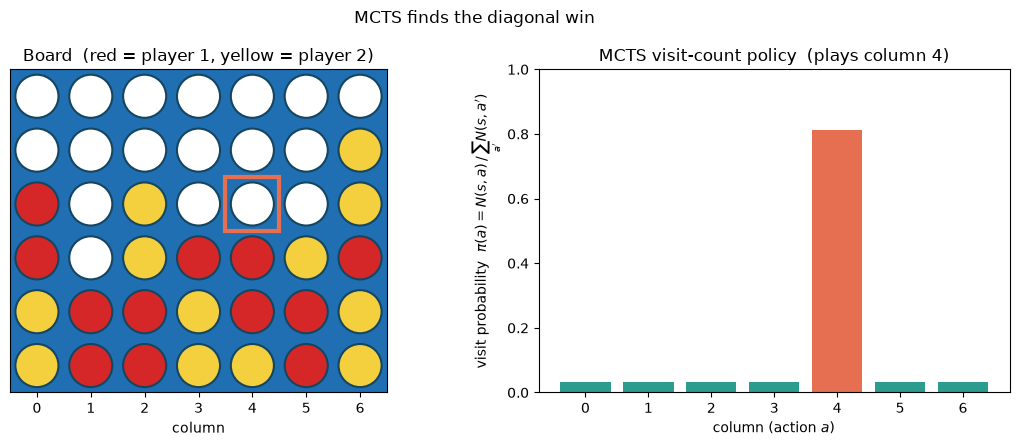

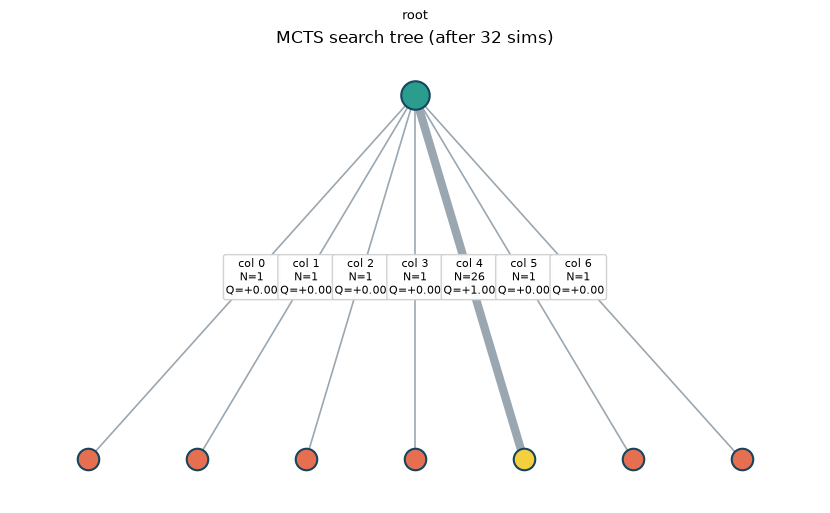

In [17]:
class DummyNet(nn.Module):

    def forward(self, boards):
        b, dev = boards.shape[0], boards.obs.device
        values = t.zeros(b, device=dev)
        logits = t.zeros(b, 7, device=dev)
        return values, logits

model = DummyNet()
board = tests.diagonal_win_red()

print("Starting position (X = Red to move):")
print(render_board(board))

root = mcts_search(board, model, env, MCTSConfig(sims=32))
visits = root.N
print("\nMCTS visit counts per column:", visits.int().tolist())
chosen = int(visits.argmax())
print(f"Most-visited column: {chosen}  ({int(visits[chosen])} of {int(visits.sum())} visits)")

board_after = place_piece(board, chosen)
print(f"\nBoard after X plays column {chosen}  (completes the diagonal):")
print(render_board(board_after, show_to_move=False))

# board + the visit-count policy pi(a) = N(s,a) / sum_a' N(s,a'), chosen column highlighted
plot_board_and_policy(board, visits / visits.sum(), chosen_action=chosen,
                      title="MCTS finds the diagonal win")
# the search tree the simulations grew: edge thickness ~ visit count, terminal leaves in yellow
plot_mcts_tree(root, max_depth=2, title="MCTS search tree (after 32 sims)")
assert chosen == 4, "MCTS should find the diagonal win"

# 3️⃣ Simulating Vectorized MCTS

> ##### Learning Objectives
>
> - Understand how we can restructure the sequential version to batch the `evaluate` stage
> of the MCTS algorithm.
> - Understand both Root Parallelization and Tree Parallelization, how they work, and
> why Root Parallelization is suited for implementing in PyTorch.
> - Build a simulated version of Root Parallelization that uses the sequential version as the backend.

Your single-game MCTS is correct but slow: one network call per simulation, on a single board.
A GPU wants **big** batches. To train in minutes we need to run **hundreds of self-play games
at once**, with every per-simulation network call batched into one forward pass.

## Root Parallelism (we do this)

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/c915b818f1b03482b0940099d669cabc66ab9815/img/ch25-root-parallel.png" width="640">

We run `batch_size` **independent games**, each with its **own search tree**. The trees never interact.
We batch them purely for GPU throughput: after all workers have finished *selection* and *expansion*, 
we collect all the nodes together and do a single forward pass through the network to *evaluate* all 
the leaves in one go. All trees then backup the values to their respective roots.

After the MCTS search is done, from each tree $T_i$ we derive a respective tree policy $\pi_i$, and 
we sample an action from each to get a set of `batch_size` many actions, 
and then step all `batch_size` many environments by one timestep.

During the training phase, we collect data $(z,s, \pi)$ from all of the environment rollouts,
and train the actor/critic network according to the loss mentioned earlier:

$$
\mathcal{L}(\theta) = \mathbb{E}_{s,z,\pi \sim \mathcal{D}} \left[ (z - v(s))^2 - \sum_{a} \pi(a|s) \log p_\theta(a|s) \right] 
+ c ||\theta||^2
$$

The fact that all trees share the same network is the only mechanism by which the trees can causally affect each other.

What gives us the sheer speed is that **everything** runs on the GPU:
* All of the trees, as well as the operations on them are written as vectorized operations on the GPU. Each operation
(walking down or up the tree, updating nodes) are all performed in lockstep, so there is no need to synchronize between threads.
The downside of this approach is the additional complication that not all leaf nodes will be at the same depth, nor do all games run
for the same number of steps. We will see how to handle this.
* The environment itself is vectorized, we can easily run many thousands of games in parallel, and the rules for updating
the game state, or checking for a winner, are all written as vectorized PyTorch operations (e.g. the operation of checking for a 4-in-a-row can be written as a convolution using kernels with hardcoded weights, see `game.py`)

At no point do we need to copy any data back and forth between the CPU or the GPU, as all the data is generated by interaction
with the environment, and for a game like Connect-4, the state space is relatively small, and the length of the games reasonably
bounded, so the memory usage is not a concern. Expect effectively ~millions of environment steps per second during training (the
environment itself can run at tens-of-millions of steps per second before the rules of the game are the bottleneck).

## Tree Parallelism (too complex for us)

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/c915b818f1b03482b0940099d669cabc66ab9815/img/ch25-tree-parallel.png" width="640">


We could have used **one shared tree** with many workers descending it simultaneously. It can be more sample-efficient as all workers pool their statistics into one tree, whereas root parallelism can be wasteful and have different trees generate duplicate statistics. But we have a different problem: Several workers running up and down the tree to update nodes leads to **node contention**: workers may have to wait for a node to be free while another worker is updating it, else we may read out a stale value, or worse, overwrite another worker's updates.

This can be solved with **mutexes**: when a worker wants to write to a node, it first locks it so no other worker can, reads the value, processes it, and then writes back the new value. With several workers waiting for the same node (e.g. the root node), this can negate the gains one hoped to get from tree parallelism. It also means you could *hash* the board state before expanding to see if the node already exists
somewhere else, and then jump there instead. This means your MCTS search is operating over a DAG (directed acyclic graph) instead of a tree,
leading to some complications on keeping track of the path from a given leaf to the root node.
This is a nightmare to write vectorized on the GPU (trust me, I tried!), 
you would instead write the tree updating code in highly optimized C++, and
then have data shuffled back and forth between the CPU and the GPU when you want to query the network (this was also a nightmare when I tried it). 

Tree Parallelism is (to the best of my knowledge) the method that DeepMind used for AlphaZero,
but **we use root parallelism** instead as it's much easier to implement as vectorized code on the GPU, 
and the speed gains from having everything be on the GPU outweigh the cost of several trees duplicating work.

### Root exploration noise (given)

Self-play has a chicken-and-egg problem: MCTS is steered by the network's prior, so it mostly explores
moves the network *already* likes — and the network only learns about moves the search explores. A
young network can collapse onto a narrow set of openings and never discover better ones.

AlphaZero's fix is to add **Dirichlet noise to the prior at the root only** — never inside the tree,
so it changes *which lines get explored* without corrupting the search's own value estimates:
$$ P(a) \;\leftarrow\; (1-\varepsilon)\,P(a) \;+\; \varepsilon\,\eta_a, \qquad \eta \sim \mathrm{Dir}(\alpha). $$

The **Dirichlet distribution** is a distribution *over probability vectors* $\eta=(\eta_1,\dots,\eta_n)$
with $\eta_i \ge 0$ and $\sum_i \eta_i = 1$ i.e. over the probability simplex. In general it has one
concentration parameter per component, $\alpha_1,\dots,\alpha_n$, but we use the **same $\alpha$ for
all of them** (a *symmetric* Dirichlet). That single $\alpha$ controls how *spiky* the samples are:

- $\alpha < 1$: **spiky / sparse**: most weight lands on one or two moves, so the noise occasionally
  gives a normally-ignored column a big boost (strong, targeted exploration).
- $\alpha = 1$: **uniform** over the simplex.
- $\alpha > 1$: **flat**: close to the centroid $(1/n,\dots,1/n)$, only a mild perturbation.

The plot below shows the Dirichlet density on the $n=3$ simplex (a triangle, one corner per
component); drag the $\alpha$ slider (log scale) to watch the mass move between the corners (spiky)
and the centre (flat). `dirichlet_root_noise` is **given**:

In [18]:
def dirichlet_root_noise(
    prior: Float[Tensor, "... 7"],
    legal: Bool[Tensor, "... 7"],
    alpha: float,
    eps: float,
) -> Float[Tensor, "... 7"]:
    """Mix Dirichlet exploration noise into the root prior (used by `expand_root` when `add_noise`).

    Noise is added only at the root, which keeps self-play exploring without distorting the rest of
    the tree. `eps = 0` returns `prior` unchanged. We use a symmetric Dirichlet (the same `alpha`
    for every column). Works with or without a leading batch dimension.

    Args:
        prior: (..., 7) the network prior at the root
        legal: (..., 7) legal-column mask (the noise is renormalised over the legal columns)
        alpha: Dirichlet concentration (smaller = spikier noise)
        eps:   mixing weight on the noise

    Returns:
        (..., 7) the mixed prior `(1 - eps) * prior + eps * noise`
    """
    noise = t.distributions.Dirichlet(
        t.full((prior.shape[-1],), alpha, device=prior.device)
    ).sample(prior.shape[:-1])
    noise = noise * legal.float()
    noise = noise / noise.sum(-1, keepdim=True).clamp_min(1e-8)
    return (1.0 - eps) * prior + eps * noise


tests.test_dirichlet_root_noise(dirichlet_root_noise)

test_dirichlet_root_noise passed


To plot the Dirichlet density on the 3-simplex; drag the alpha slider (log scale, 0.01 -> 10).
```python
utils.plot_dirichlet_simplex()
```

In [19]:
utils.plot_dirichlet_simplex()

## A stepping stone: batch the network, keep the Python trees


Before we rewrite everything as vectorised tensor ops, here's a much gentler version that already
captures the two ideas that make root parallelism fast: 

We keep `B` completely independent single-game trees, each driven by section 2's `select` and
`backup`; expansion and evaluation are the class's own batched `_expand` / `_evaluate_batch`.
Per MCTS simulation we:

1. **select + expand** each tree, *sequentially* with a plain Python `for` loop, collecting one
   leaf node per tree (pretending they run in parallel);
2. **evaluate** all `B` leaves in a **single fixed-size forward pass** through the network;
3. **backup** each tree, again *sequentially* with a `for` loop (pretending they run in parallel).

In principle both loops could be accelerated by dispatching multiple worker processes:

```python
from concurrent.futures import ProcessPoolExecutor

#each piece of data processed individually by `work`
def work(x):
    ...
    return something

data = [1, 2, 3, 4, 5]
with ProcessPoolExecutor() as ex:                  
    results = list(ex.map(work, data))
``` 
but the overhead of spawning processes, and copying data CPU <-> GPU would kill us. (Threads would
not help here either: the tree walks are pure Python, so the Global Interpreter Lock serialises them anyway.)


Two details bring it closer to the real vectorised search:

- **A shared board pool.** Rather than every node owning its own `(1,)` `Board`,
   we keep one `pool` `Board` of batch shape
  `(B, MAXN)` and each node just stores an integer `slot` pointing into it. The root boards
  go in once (`pool[:, 0] = root_boards`); the per-simulation batch is then a single **gather** out
  of the pool, with no packing/unpacking. This is exactly the storage scheme of the vectorised
  `Tree` below.
- **A fixed-size batch.** We push *all* `B` leaves through the network every simulation, **including
  terminal ones** whose value we already know. Re-evaluating a terminal leaf is wasted compute, but
  a constant `B`-shaped forward pass every step is both faster on the GPU and faithful to the
  vectorised search, where the batch shape never changes. This also works better with `t.compile`
  for extra speed.

The gains are minimal (I measured **~1.8x speed-up** against the purely sequential version), 
but it's a good starting point.

In [20]:
class SimulatedBatchedMCTS:
    """Root-parallel MCTS over `B` independent trees, with the network call batched across trees.

    A clarity-first stand-in for the vectorised `BatchedMCTS` below, with the **same interface**: hold
    an `env` + `cfg`, then call `.search(model, root_boards)`. Every tree is a normal
    Python `Node` tree driven by the section 2 `select`/`backup` functions, looped over the batch. The two
    things it borrows from the vectorised version are (i) a single board `pool` that every node indexes
    by `slot` (so boards never need packing/unpacking), and (ii) a fixed-size forward pass over all
    `B` leaves every simulation, terminal leaves included.

    Each node stores an integer `slot` instead of its own board: its position lives at
    `pool[game, slot]`. (`Node.board` is left as `None` since none of `select`/`backup` read it.)
    """

    def __init__(self, env, cfg):
        self.env, self.cfg = env, cfg

    @t.no_grad()
    def _expand(self, pool, nptr, game, node, action):
        """Section 2's `expand` function, but the child's board is written into the pool and the child stores its `slot`."""
        parent_board = pool[game, node.slot]                                # one game's board, unbatched
        next_board, done, reward = self.env.step(parent_board, action)      # done, reward: python scalars
        slot = nptr[game]
        nptr[game] += 1
        pool[game, slot] = next_board
        child = Node(board=None, is_terminal=done, terminal_value=-reward,
                     parent=node, parent_action=action)
        child.slot = slot
        node.children[action] = child
        return child

    @t.no_grad()
    def _evaluate_batch(self, model, pool, batch_idx, nodes):
        """Evaluate all `B` leaves in ONE fixed-size forward pass; return one value per node.

        Terminal leaves are forwarded too (their board is gathered from the pool like any other) even
        though we throw away the network's output and use the value stored at creation. The constant
        `B`-shaped batch matches the vectorised search and is faster than a ragged one.
        """
        slots = t.tensor([node.slot for node in nodes], device=batch_idx.device)
        boards = pool[batch_idx, slots]                                    # (B,) Board, one gather
        value, logits = model(boards)                                      # <- one batched call, all B nodes
        value, logits = value.float(), logits.float()                      # keep node stats fp32 even if the net runs in bf16
        legal = self.env.legal_action_mask(boards)
        P = t.softmax(t.where(legal, logits, -t.inf), dim=-1)
        value, legal, P = value.cpu(), legal.cpu(), P.cpu()
        values = []
        for b, node in enumerate(nodes):
            if node.is_terminal:
                values.append(node.terminal_value)    # value known at creation; net output discarded
            else:
                node.legal = legal[b]
                node.P = P[b]
                values.append(float(value[b]))
        return values

    @t.no_grad()
    def search(self, model, root_boards: Board, add_noise: bool = False) -> Float[Tensor, "B 7"]:
        """Run `cfg.sims` simulations of root-parallel MCTS from the (B,) `root_boards`; return (B, 7)
        root visit counts. Same signature as `BatchedMCTS.search`, just sequential-over-trees (so much slower)."""
        cfg = self.cfg
        B, device = root_boards.shape[0], root_boards.obs.device
        batch_idx = t.arange(B, device=device)

        # Shared board pool: every node just stores a `slot` into this, so we never pack/unpack boards.
        # At most one node is added per simulation, so `cfg.sims + 1` slots per game (slot 0 = root)
        # can never overflow.
        pool = Board(t.zeros((B, cfg.sims + 1, *root_boards.obs.shape[1:]), device=device),
                     t.zeros((B, cfg.sims + 1), dtype=t.bool, device=device))
        pool[:, 0] = root_boards                     # drop in all root boards at once (slot 0)
        nptr = [1] * B                               # next free slot per game

        # construct the roots of the trees, each pointing at slot 0 of its game's pool
        roots = []
        for b in range(B):
            node = Node(board=None)
            node.slot = 0
            roots.append(node)

        # evaluate every root in one forward pass to set its P / legal (as section 2 does for its single root)
        self._evaluate_batch(model, pool, batch_idx, roots)
        if add_noise:  # batched Dirichlet noise on the root priors, exactly as `expand_root` does it
            P = dirichlet_root_noise(t.stack([r.P for r in roots]), t.stack([r.legal for r in roots]),
                                     cfg.dirichlet_alpha, cfg.dirichlet_eps)
            for b, root in enumerate(roots):
                root.P = P[b]

        for _ in range(cfg.sims):
            # 1. SELECT + EXPAND each tree sequentially, collecting one leaf per tree
            leaves = []
            for game, root in enumerate(roots):
                node, action = select(root, cfg.c_puct)
                leaf = node if node.is_terminal else self._expand(pool, nptr, game, node, action)
                leaves.append(leaf)
            # 2. EVALUATE every leaf in a single, fixed-size forward pass through the network
            values = self._evaluate_batch(model, pool, batch_idx, leaves)
            # 3. BACKUP each tree sequentially
            for leaf, value in zip(leaves, values):
                backup(leaf, value)
        return t.stack([root.N for root in roots]).to(device)      # (B, 7), on the input's device

tests.test_simulated_batched_mcts(SimulatedBatchedMCTS)

test_simulated_batched_mcts passed (simulated <-> single-game <-> vectorised equivalence)


Unsurprisingly, this barely helps, as the largest bottleneck is just looping through all the tree updates:
benchmarking this against the fully-accelerated version below (sims=32, `NVIDIA RTX A4000, 16GB RAM`):

| B | seq-trees + batched-net | batched-everything | speedup | GPU Mem |
|---:|---:|---:|---:|---:|
| 64 | 716 | 4,751 | 6.6× | nil |
| 256 | 704 | 19,572 | 27.8× | nil |
| 1,024 | 689 | 78,325 | 114× | 0.12 GB |
| 4,096 | 691 | 189,903 | **275×** | 0.44GB |
| 8,192 | 700* | 208,591 | **298×** | 0.86 GB |
| 16,384 | 700* | 220,152 | **314×** | 1.71 GB |
| 32,768 | 700* | 226,132 | **323×** | 3.41 GB |
| 65,536 | 700* | **229,872** | **328×** | 6.80 GB |
| 131,072 | 700* | **OOM** | - | > 16 GB |

*Estimated based on the average over lower batches as it took too long to run,
and that we don't expect larger batch sizes to help the sequential version anyway.

As we can see, the sequential version is flat at ~700 env-steps/s even with small batch
sizes, as processing the trees is by far the bottleneck. Once we vectorize everything,
it saturates at roughly ~220k env-steps/s, a **300x speedup**.

For now, we will take for granted the vectorized implementation of MCTS, which provides 
a functionally identical `BatchedMCTS.search` method as `SimulatedBatchedMCTS.search` above,
but implemented such that selection, expansion and backup are 
also vectorized.

As a bonus at the end you can try implementing the vectorized version yourself.

# 4️⃣ Self-Play & Training

> ##### Learning Objectives
>
> - Implement the self-play sampler: the tree policy, the network policy, and using the critic to estimate the value of rollouts.
> - Understand the loss function for the network and how it distills the planning provided by the tree search.
> - Train an agent to match a perfect solver's moves (and hopefully beat you too!)

Now we close the loop. We need two ingredients: a **sampler** that turns MCTS into training
data, and a **loss** that trains the network on that data. All the boring parts
we've already seen on PPO day (the replay buffer, the optimiser, the generation loop)
are given in the `AlphaZeroTrainer` below.

## The value target: `compute_z_targets`

During a self-play generation we record, for every game `b` and move `t`, whether the move
ended the game (`dones[b,t]`) and the mover's reward (`rewards[b,t]`). The **value target** `z[b,t]`
is the eventual outcome of *that game*, **from the perspective of the mover at state `t`**: 
so it flips sign every [ply](https://en.wikipedia.org/wiki/Ply_(game_theory)), 
and resets at each game boundary (games auto-reset and replay within a generation).

The clean way to compute this is a **single backward scan** over time. Going from the last move
to the first: if move `t` was terminal, the running value is just its reward; otherwise it's the
**negation** of the running value from `t+1` (negamax again). This propagates each game's
outcome back to all its states with the correct alternating signs.

This is a similar function to `compute_returns` from vanilla 
policy-gradient, but with the alternating signs of the negamax.

Worked example: \
Consider a batch of three games. 
The first game lasted two plies before
a win, the second game lasted four plies, and the third game lasted five plies before a draw. 
The corresponding `done`
and `reward` tensors are:

```python
dones  = t.Tensor([[0,0,1,1,1,1],
                       [0,0,0,0,1,1],
                       [0,0,0,0,0,1]]).bool()
                       
reward = t.Tensor([[0,0,1,0,0,0],
                       [0,0,0,0,1,0],
                       [0,0,0,0,0,0]]).float()
```

Recall that it is not actually possible for self-play to
ever give a negative reward, as a player can only ever win or draw
after making their move. A player cannot move and then immediately lose.
(Technically `env.step` *does* return `-2` for an **illegal** move but MCTS
only ever visits legal columns, so this would never happen anyway.)

The corresponding `z` tensor would be:
```python
z = tensor([[ 1., -1.,  1.,  0.,  0.,  0.],
            [ 1., -1.,  1., -1.,  1.,  0.],
            [-0.,  0., -0.,  0., -0.,  0.]])
```

### Exercise - implement `compute_z_targets`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 15-20 minutes on this exercise.
> ```

Don't hurt yourself trying too hard to vectorize this, a for loop
over timesteps $t = T, T-1, \ldots, 1$ is fine (which translates
to `for step in range(timesteps - 1, -1, -1)` in Python). Don't name the loop variable `t`: it would
shadow `torch`.

In [21]:
def compute_z_targets(
    dones: Bool[Tensor, "batch timesteps"], 
    rewards: Float[Tensor, "batch timesteps"]
) -> Float[Tensor, "batch timesteps"]:
    """Negamax value targets for a batch of `B` self-play games of `T` plies.

    Walking each game backwards from its terminal rewards, the target at each ply is the game's final
    reward with its sign flipped once per step back. Every recorded value in this project is from the
    perspective of the player about to move; stepping back one ply changes whose turn it is, hence the
    negation (negamax: good for the mover is bad for its parent).

    Args:
        dones: (batch, timesteps) marks the ply where each game ended
        rewards:  (batch, timesteps) rewards to the mover at each ply (nonzero only where dones)

    Returns:
        (batch, timesteps) the mover-perspective outcome `z` for every recorded state
    """
    batch, timesteps = dones.shape
    z = t.zeros((batch, timesteps), device=dones.device)
    timesteps = rewards.shape[1]
    running = rewards[:, -1]
    for step in range(timesteps - 1, -1, -1):
        running = t.where(dones[:, step], rewards[:, step], -running)
        z[:, step] = running
    return z


tests.test_compute_z_targets(compute_z_targets)

test_compute_z_targets passed


<details><summary>Solution</summary>

```python
def compute_z_targets(
    dones: Bool[Tensor, "batch timesteps"], 
    rewards: Float[Tensor, "batch timesteps"]
) -> Float[Tensor, "batch timesteps"]:
    """Negamax value targets for a batch of `B` self-play games of `T` plies.

    Walking each game backwards from its terminal rewards, the target at each ply is the game's final
    reward with its sign flipped once per step back. Every recorded value in this project is from the
    perspective of the player about to move; stepping back one ply changes whose turn it is, hence the
    negation (negamax: good for the mover is bad for its parent).

    Args:
        dones: (batch, timesteps) marks the ply where each game ended
        rewards:  (batch, timesteps) rewards to the mover at each ply (nonzero only where dones)

    Returns:
        (batch, timesteps) the mover-perspective outcome `z` for every recorded state
    """
    batch, timesteps = dones.shape
    z = t.zeros((batch, timesteps), device=dones.device)
    running = t.zeros((batch,), device=dones.device)
    for step in range(timesteps - 1, -1, -1):
        running = t.where(dones[:, step], rewards[:, step], -running)
        z[:, step] = running
    return z


tests.test_compute_z_targets(compute_z_targets)
```
</details>

## The AlphaZero loss: `compute_az_loss`

Given the network's `value (N,)` and `logits (N,7)` on a minibatch, and the targets
`pi (N,7)` (MCTS visit distribution) and `z (N,)` (game outcome), the loss is

$$\mathcal L = \underbrace{-\sum_a \pi_a \log \text{softmax}(\text{logits})_a}_{\text{policy cross-entropy}}
            \;+\; c_v \underbrace{(\text{value} - z)^2}_{\text{value MSE}},$$

averaged over the minibatch (the weight decay is not included explicitly in the loss
as it is handled by the optimiser).

### Exercise - implement `compute_az_loss`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 10-15 minutes on this exercise.
> ```

In [22]:
def compute_az_loss(
    value: Float[Tensor, "N"],
    logits: Float[Tensor, "N 7"],
    pi: Float[Tensor, "N 7"],
    z: Float[Tensor, "N"],
    value_coef: float = 1.0,
) -> Float[Tensor, ""]:
    """Scalar AlphaZero loss over a minibatch of `N` positions: policy cross-entropy + value MSE.

    Loss = mean of `-sum_a pi_a log softmax(logits)_a` + `value_coef * (value - z)^2`.

    Args:
        value:      (N,) critic outputs
        logits:     (N, 7) actor outputs
        pi:         (N, 7) MCTS visit-count policy target
        z:          (N,) game-outcome value target
        value_coef: weight on the value-MSE term

    Returns:
        scalar tensor: the mean total loss
    """
    assert value.shape == z.shape
    assert logits.shape == pi.shape
    mse = value_coef*(value - z)**2
    mse = mse.mean()
    cross_ent = t.sum(pi*t.log(t.softmax(logits, dim = -1)), dim = -1)
    cross_ent = cross_ent.mean()
    return -1*cross_ent + mse


tests.test_compute_az_loss(compute_az_loss)

test_compute_az_loss passed


<details><summary>Solution</summary>

```python
def compute_az_loss(
    value: Float[Tensor, "N"],
    logits: Float[Tensor, "N 7"],
    pi: Float[Tensor, "N 7"],
    z: Float[Tensor, "N"],
    value_coef: float = 1.0,
) -> Float[Tensor, ""]:
    """Scalar AlphaZero loss over a minibatch of `N` positions: policy cross-entropy + value MSE.

    Loss = mean of `-sum_a pi_a log softmax(logits)_a` + `value_coef * (value - z)^2`.

    Args:
        value:      (N,) critic outputs
        logits:     (N, 7) actor outputs
        pi:         (N, 7) MCTS visit-count policy target
        z:          (N,) game-outcome value target
        value_coef: weight on the value-MSE term

    Returns:
        scalar tensor: the mean total loss
    """
    assert value.shape == z.shape
    assert logits.shape == pi.shape
    logprobs = F.log_softmax(logits, dim=-1)
    policy_loss = -(pi * logprobs).sum(-1).mean()
    critic_loss = F.mse_loss(value, z)
    # alternative non-mse solution:
    # critic_loss = ((value - z) ** 2).mean()
    return policy_loss + value_coef * critic_loss


tests.test_compute_az_loss(compute_az_loss)
```
</details>

### Training Hyperparameters

In [23]:
@dataclass
class AZConfig:
    """All the knobs for self-play + training. The defaults are a fast in-notebook recipe (8192
    self-play games/gen, 16 sims/move, 8 generations, minibatch 2048) that reaches ~85% Pons-solver
    accuracy in ~3-4 min on a GPU (~2 min on an RTX 5090). For a stronger agent raise `sims` to 64 and `num_generations` to ~50
    (≈25k optimiser steps); to run faster still, dial `num_games` / `sims` / `num_generations` down.

    c_puct (1.5->1.0), lr (1e-3->5e-3) and buffer_gens (8->4) were tuned by a
    full-run sweep (pons_CE ~0.466->0.420 at ~1/4 the compute); every gain came from fresher self-play
    data — capacity/loss/regularisation were inert. Usable lr band ~3e-3..6e-3 (≥7e-3 is seed-unstable)."""
    # self-play / data
    num_games: int = 8192          # parallel self-play games per generation (4096 -> 8192: ~1.5x the games/sec, fewer gens needed)
    sims: int = 16                 # MCTS simulations per move (16 = the fast default; 32 learns about as well as 64 at ~2x the self-play speed, and 64 gives the strongest run)
    num_generations: int = 8        # training generations (~85% Pons acc in ~3-4 min; raise to ~50 for the full recipe)
    buffer_gens: int = 4           # replay buffer = the last this-many generations (tuned 8->4: fresher data)
    moves_per_gen: int = 42        # plies per generation (a full Connect-4 game)
    temperature: float = 1.0       # visit-count sampling temperature, used for every ply
    # MCTS / exploration
    c_puct: float = 1.0               # tuned 1.5->1.0 (full-run sweep, both seeds)
    max_depth: int = 42
    dirichlet_alpha: float = 10 / 7   # ≈ 1.43, root exploration-noise concentration
    dirichlet_eps: float = 0.25       # weight of the root Dirichlet noise
    # optimiser / schedule
    lr: float = 5e-3               # initial learning rate (tuned 1e-3->5e-3; >=7e-3 is seed-unstable)
    lr_min: float = 2e-5           # cosine-decay target over the run
    weight_decay: float = 1e-4
    grad_clip: float = 1.0         # global grad-norm clip
    minibatch: int = 2048          # 1024 -> 2048: ~2x faster training pass (1024 leaves the GPU ~25% busy), same learning
    value_coef: float = 1.0        # weight on the value-MSE loss term
    # precision: bf16 autocast on by default if supported
    use_bf16: bool = device.type == "cuda" and t.cuda.is_bf16_supported(including_emulation=False)
    # logging
    use_wandb: bool = False        # log loss / lr / Pons metrics to Weights & Biases
    wandb_project: str = "alphazero-connect4"

## The replay buffer (given)

Self-play and training talk through a small **given** `ReplayBuffer`, in the same spirit as the VPG
rollout buffer from [2.2]. It preallocates the per-generation rollout tensors once, you `write` one
ply at a time, and `end_generation` turns the finished rollout into flat `(boards, pi, z)` training
examples (with the negamax value targets computed and dropping states whose game didn't finish) keeping
the last `cfg.buffer_gens` generations. `minibatches` then hands back a shuffled list of minibatches over
those examples. This keeps the exercises tiny: `self_play_step` just `write`s each ply, and the
training loop just iterates `minibatches(...)` calling your `training_step`.

In [24]:
class ReplayBuffer:
    """Given. Rolling replay of the last `cfg.buffer_gens` self-play generations.

    Usage: `write(...)` one ply at a time, `end_generation()` after each generation (computes value
    targets, drops unfinished states, flattens over (game, ply), evicts the oldest generation), then
    `minibatches(mb)` for a shuffled list of training minibatches. Mirrors the VPG rollout buffer from [2.2]."""

    def __init__(self, cfg: AZConfig, device):
        self.cfg, self.device = cfg, device
        B, T = cfg.num_games, cfg.moves_per_gen
        # preallocated rollout for the CURRENT generation (written one ply at a time, in place)
        self.boards = Board(t.empty((B, T, 3, 6, 7), device=device),
                            t.empty((B, T), dtype=t.bool, device=device))
        self.pi = t.empty((B, T, 7), device=device)
        self.dones = t.empty((B, T), dtype=t.bool, device=device)
        self.rews = t.empty((B, T), device=device)
        self.t = 0                 # next free ply slot in the current generation
        self.gens = []             # rolling list of finished generations, each a flat (boards, pi, z)

    def write(self, boards, pi, done, reward):
        """Record one ply of the current generation into row `self.t`, then advance."""
        self.boards[:, self.t] = boards
        self.pi[:, self.t] = pi
        self.dones[:, self.t] = done
        self.rews[:, self.t] = reward
        self.t += 1

    def end_generation(self):
        """Finish the current generation: compute negamax `z`, keep only states whose game finished
        (reverse cumulative-OR of dones over time), flatten over (game, ply), append to the rolling
        buffer (evicting the oldest), and reset the write pointer."""
        z = compute_z_targets(self.dones, self.rews)                          # (B, T)
        keep = (self.dones.int().flip(-1).cumsum(-1).flip(-1) > 0).reshape(-1)
        self.gens.append((self.boards.reshape(-1)[keep],
                          self.pi.reshape(-1, 7)[keep],
                          z.reshape(-1)[keep]))
        if len(self.gens) > self.cfg.buffer_gens:
            self.gens.pop(0)
        self.t = 0

    def minibatches(self, batch_size):
        """Snapshot the whole buffer into a freshly shuffled list of `(boards, pi, z)` minibatches
        (one epoch). The last, partial batch is dropped so every batch is exactly `batch_size` (great
        for a fixed compiled forward), but only when there's at least one full batch, so tiny configs
        still train."""
        boards = Board.cat([g[0] for g in self.gens])
        pi = t.cat([g[1] for g in self.gens])
        z = t.cat([g[2] for g in self.gens])
        perm = t.randperm(len(z), device=z.device)
        if len(perm) >= batch_size:
            perm = perm[: len(perm) // batch_size * batch_size]   # drop the last partial batch
        return [(boards[idx], pi[idx], z[idx]) for idx in perm.split(batch_size)]

    def reset(self):
        self.gens, self.t = [], 0

    def __len__(self):
        return sum(len(g[2]) for g in self.gens)

## Evaluating against a perfect solver (given)

Recall that Connect4 is a solved game, and fast solvers exist that can in milliseconds
report back the optimal move for any given position (with the use of a pre-computed
[opening book](https://en.wikipedia.org/wiki/Chess_opening_book_(computers))).

We make use of the [Pascal Pons' perfect Connect-4 solver](https://github.com/PascalPons/connect4),
and pregenerate ~6700 board positions that have been labelled with the optimal move
for each position, as well as pre-filtered for positions that are decisive 
(i.e. it is not the case that all moves lead to a loss/win/draw under optimal play on both sides).

The given `evaluate_policy` runs the
network over this set in one batched forward pass, and reports back the metrics:

* **`acc`** — fraction of positions where the policy's top move is solver-optimal,
* **`ce`** — the policy cross-entropy against the optimal-move set: $ - \log \sum_{a : a \text{ is optimal}} p_\theta(a|s) $, a smoother signal than `acc`.

This eval is far cheaper than playing out games as it requires only one batched forward pass, while
providing a lot of feedback on how well the policy is performing. 
You should see `acc` climb (and `ce` fall) over a handful of generations.

If you like, have a look in the `pascal_pons` directory to see how the dataset was generated. It's
included in the repo for convenience. It basically downloads the opening book and Pascal Pons' solver,
generates a series of games between epsilon-greedy heuristic policies (take a win, block a loss, else centre-weighted random), and labels the positions with the optimal move.
It then filters out positions that are not decisive or duplicates, and saves the remaining positions to a file.

It's also available [here](https://huggingface.co/datasets/davidquarel/connect4-pons-eval) on HuggingFace just
in case, which will auto-download the dataset the first time you run `evaluate_policy`.

In [25]:
from pascal_pons.eval_pons import evaluate_policy

### Exercise - implement `self_play_step`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

**`self_play_step`** should run one ply of self-play, given the current `boards` (a `Board` of batch
shape `(num_games,)`, all games at once):

1. **Search**: run the batched MCTS to get the root visit counts (with root noise: `add_noise=True`).
2. **Tree policy**: turn the visit counts into the training target `pi = self.visit_policy(root_N)`
   (at $\tau = 1$, i.e. proportional to the visit counts).
3. **Act**: sample one action per game (`t.multinomial`) from `self.visit_policy(root_N, self.cfg.temperature)`
   and `step` the environment.
4. **Record** the ply into the given replay buffer: `self.buffer.write(boards, pi, done, reward)`.

Return `(next_boards, done)`. The given `self_play` loop calls this `moves_per_gen` times and calls
`self.buffer.end_generation()` at the end. (Whose turn it is travels with the boards, and `env.step`
auto-resets finished games, so there's no other bookkeeping.)
The buffer handles the value targets, masking out unfinished states, the rolling replay, and serving minibatches.


### Exercise - implement `visit_policy`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵⚪⚪⚪
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement the `visit_policy` method, which turns the root visit counts into the tree policy
$$
\pi(a | s) = \frac{N(s, a)^{1 / \tau}}{\sum_{a'} N(s, a')^{1 / \tau}}
$$
for every game at once. It does two jobs: at $\tau = 1$ (plain visit-count proportions) it is the
**target policy** we train the network on, and at $\tau$ = `cfg.temperature` it is the distribution we
**sample the move we actually play** from. The temperature is an exploration knob for the played move
only; the training target stays temperature-free. (The two coincide at the default $\tau = 1$.)

### Exercise - implement `training_step`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10-15 minutes on this exercise.
> ```

**`training_step`** : one optimiser step on a minibatch `(boards, pi, z)`: 
* forward the net, compute the AlphaZero loss with `compute_az_loss`, do an optimizer step,
and then return the scalar loss. Optionally, you can also clip the gradient to `cfg.grad_clip`
with `nn.utils.clip_grad_norm_`.

In [26]:
class AlphaZeroTrainer:
    """Owns the full per-generation loop described below. Each generation `train()` runs:

    1. `self_play()`: `moves_per_gen` plies of batched self-play with the frozen net
       (your `self_play_step` per ply, writing `(boards, π, done, reward)` into `self.buffer`),
       then `buffer.end_generation()` turns the rollout into flat `(boards, π, z)` training rows.
    2. one supervised pass over `buffer.minibatches(minibatch)` (your `training_step` per batch),
    3. a cosine LR-schedule step and (periodically) `evaluate()` against the Pons solver.

    Attributes: `env` (Connect4Env), `cfg` (AZConfig), `model` (Connect4Model), `opt` (AdamW),
    `mcts` (BatchedMCTS — built from cfg's sims/c_puct/dirichlet settings), `buffer` (ReplayBuffer).
    """
    def __init__(self, env, cfg, model):
        self.env = env
        self.cfg = cfg
        self.device = env.device
        self.model = model
        self.opt = t.optim.AdamW(self.model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
        self.mcts = BatchedMCTS(env, MCTSConfig(
            sims=cfg.sims, c_puct=cfg.c_puct, max_depth=cfg.max_depth,
            dirichlet_alpha=cfg.dirichlet_alpha, dirichlet_eps=cfg.dirichlet_eps))
        self.buffer = ReplayBuffer(cfg, self.device)


    def visit_policy(self, root_N: Float[Tensor, "B 7"], temperature: float = 1.0) -> Float[Tensor, "B 7"]:
        """The tree policy π(a) ∝ N(s,a)^(1/τ), per game. At τ = 1 this is the training target; with
        `cfg.temperature` it is the distribution the played move is sampled from.

        Args:
            root_N:      (B, 7) root visit counts from the MCTS search
            temperature: τ; 1.0 is proportional to visit counts, →0 approaches greedy argmax,
                         larger flattens the distribution

        Returns:
            (B, 7) probabilities, each row summing to 1. Actions with zero visits get probability 0.
        """

        return root_N**(1/temperature)/(t.sum(root_N**(1/temperature), dim = -1))[:, None]

    @t.no_grad()
    def self_play_step(self, boards: Board) -> tuple[Board, Bool[Tensor, "B"]]:
        """One ply of self-play for all `num_games` games at once: MCTS -> tree policy -> sample ->
        step -> record the ply into `self.buffer`.

        Args:
            boards: (B,) current boards

        Returns:
            next_boards: (B,) boards after the move (finished games auto-reset to an empty board)
            done:        (B,) whether the move ended each game
        """
        root_counts = self.mcts.search(self.model,boards, add_noise=True)
        probs = self.visit_policy(root_counts)
        dist = t.distributions.categorical.Categorical(probs = probs)
        action = dist.sample()
        next_board, done, reward = self.env.step(boards, action)
        self.buffer.write(boards, probs, done, reward)
        return next_board, done


    @t.no_grad()
    def self_play(self, progress: bool = True):
        """Play one generation: `num_games` games for `moves_per_gen` plies, calling your
        `self_play_step` each ply (which `write`s into `self.buffer`), then finalise the generation in
        the buffer. The buffer handles the value targets, masking and replay -- nothing to return.

        The ply loop is wrapped in a tqdm bar with `unit_scale` (like the 2.2 SPS bar) so you get a
        live, SI-formatted env-steps/sec readout during self-play rather than one update per generation."""
        B, T = self.cfg.num_games, self.cfg.moves_per_gen
        boards = self.env.reset(B)
        self.model.eval()
        # each ply runs `sims` batched env.steps over all B games (one per MCTS simulation), so the
        # generation does B * T * sims env transitions in total -- tqdm turns that into a live rate,
        # and the postfix shows cumulative MCTS simulations done out of `moves_per_gen * sims`.
        total_sims = T * self.cfg.sims
        bar = tqdm(total=B * T * self.cfg.sims, unit=" env steps", unit_scale=True,
                   desc="self-play", leave=False, disable=not progress)
        
        with t.autocast(self.device.type, dtype=t.bfloat16, enabled=self.cfg.use_bf16):
            for ply in range(T):
                boards, _ = self.self_play_step(boards)   # finished games auto-reset (red to move)
                bar.update(B * self.cfg.sims)
                bar.set_postfix_str(f"sims {(ply + 1) * self.cfg.sims}/{total_sims}")
        bar.close()
        self.buffer.end_generation()

    def training_step(self, boards, pi, z):
        """One optimiser step on a single minibatch `(boards, pi, z)`: forward the net, compute the
        AlphaZero loss (`compute_az_loss`), zero the grads (`self.opt.zero_grad(set_to_none=True)`),
        backprop, clip the gradient norm to `cfg.grad_clip`, and step the optimiser. AlphaZero's update is just supervised learning -- regress the value head onto
        `z` and the policy head onto `pi`.

        Args:
            boards: (mb,) Board minibatch
            pi:  (mb, 7) MCTS policy targets
            z:   (mb,) value targets

        Returns:
            float: the minibatch loss
        """
        self.opt.zero_grad()
        value, logits = self.model(boards)
        loss = compute_az_loss(value, logits, pi, z)
        loss.backward()
        self.opt.step()
        return loss

    @t.no_grad()
    def evaluate(self) -> dict:
        """Given. Score the current network against the frozen Pons solver set (policy accuracy /
        cross-entropy / value sign-accuracy). One cached forward pass; see the section above."""
        return evaluate_policy(self.model, self.env)

    def train(self, num_generations=None, eval_every=1):
        """Given. The full training loop -- you don't need to touch this. Each generation: run
        self-play into the buffer, do one supervised pass over the buffer's minibatches
        (calling your `training_step`), step the cosine LR schedule, and periodically `evaluate`
        against the Pons solver. Logs loss / lr / eval to a tqdm bar (and to wandb if `cfg.use_wandb`)."""
        import time
        num_generations = num_generations or self.cfg.num_generations
        # cosine-decay the LR; schedule over a >=10-gen horizon so a short quick run doesn't crater the
        # LR before it finishes (a 6-gen T_max=6 cosine would decay to lr_min by the last gen and stall).
        sched = t.optim.lr_scheduler.CosineAnnealingLR(self.opt, T_max=max(num_generations, 10), eta_min=self.cfg.lr_min)
        # effective env transitions/sec for the tqdm bar: each generation steps the env
        # num_games * moves_per_gen * sims times (one batched env.step per MCTS simulation). It's just a
        # counter + a clock, so it adds no per-step overhead -- handy for spotting when self-play bottlenecks.
        t0, env_steps = time.time(), 0
        steps_per_gen = self.cfg.num_games * self.cfg.moves_per_gen * self.cfg.sims
        if self.cfg.use_wandb:
            import wandb
            wandb.init(project=self.cfg.wandb_project, config=asdict(self.cfg))
        metrics = {}
        bar = tqdm(range(1, num_generations + 1))
        for gen in bar:
            self.self_play()                                       # fill + roll the replay buffer
            env_steps += steps_per_gen
            self.model.train()
            batches = self.buffer.minibatches(self.cfg.minibatch)
            total_loss, n_batches = 0.0, 0
            tbar = tqdm(batches, desc="train", leave=False)       # one supervised pass over the buffer
            for boards, pi, z in tbar:
                with t.autocast(self.device.type, dtype=t.bfloat16, enabled=self.cfg.use_bf16):
                    total_loss += self.training_step(boards, pi, z)
                n_batches += 1
                tbar.set_postfix_str(f"loss={total_loss / n_batches:.3f}")   # live running-mean loss
            loss = total_loss / max(n_batches, 1)
            sched.step()
            if eval_every and gen % eval_every == 0:
                metrics = self.evaluate()                          # Pons solver benchmark
            lr = sched.get_last_lr()[0]
            sps = env_steps / max(time.time() - t0, 1e-9)          # effective env steps/sec (cumulative)
            bar.set_postfix_str(f"loss={loss:.3f}  acc={metrics.get('pons/acc', float('nan')):.3f}  "
                                f"ce={metrics.get('pons/ce', float('nan')):.3f}  env/s={fmt_si(sps)}")
            if self.cfg.use_wandb:
                wandb.log({"generation": gen, "loss": loss, "lr": lr, "env_steps_per_sec": sps, **metrics})
        if self.cfg.use_wandb:
            wandb.finish()
        return self.model


tests.test_visit_policy(AlphaZeroTrainer)
tests.test_self_play_step(AlphaZeroTrainer)
tests.test_training_step(AlphaZeroTrainer)

test_visit_policy passed
test_self_play_step passed
test_training_step passed


/root/ARENA_materials/chapter2_rl/exercises/part5_mcts_alphazero/tests.py:1121: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  loss = float(loss)


<details><summary>Solution</summary>

```python
class AlphaZeroTrainer:
    """Owns the full per-generation loop described below. Each generation `train()` runs:

    1. `self_play()`: `moves_per_gen` plies of batched self-play with the frozen net
       (your `self_play_step` per ply, writing `(boards, π, done, reward)` into `self.buffer`),
       then `buffer.end_generation()` turns the rollout into flat `(boards, π, z)` training rows.
    2. one supervised pass over `buffer.minibatches(minibatch)` (your `training_step` per batch),
    3. a cosine LR-schedule step and (periodically) `evaluate()` against the Pons solver.

    Attributes: `env` (Connect4Env), `cfg` (AZConfig), `model` (Connect4Model), `opt` (AdamW),
    `mcts` (BatchedMCTS — built from cfg's sims/c_puct/dirichlet settings), `buffer` (ReplayBuffer).
    """
    def __init__(self, env, cfg, model):
        self.env = env
        self.cfg = cfg
        self.device = env.device
        self.model = model
        self.opt = t.optim.AdamW(self.model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
        self.mcts = BatchedMCTS(env, MCTSConfig(
            sims=cfg.sims, c_puct=cfg.c_puct, max_depth=cfg.max_depth,
            dirichlet_alpha=cfg.dirichlet_alpha, dirichlet_eps=cfg.dirichlet_eps))
        self.buffer = ReplayBuffer(cfg, self.device)


    def visit_policy(self, root_N: Float[Tensor, "B 7"], temperature: float = 1.0) -> Float[Tensor, "B 7"]:
        """The tree policy π(a) ∝ N(s,a)^(1/τ), per game. At τ = 1 this is the training target; with
        `cfg.temperature` it is the distribution the played move is sampled from.

        Args:
            root_N:      (B, 7) root visit counts from the MCTS search
            temperature: τ; 1.0 is proportional to visit counts, →0 approaches greedy argmax,
                         larger flattens the distribution

        Returns:
            (B, 7) probabilities, each row summing to 1. Actions with zero visits get probability 0.
        """
        temp_visits = root_N ** (1 / temperature)
        return temp_visits / temp_visits.sum(-1, keepdim=True)

    @t.no_grad()
    def self_play_step(self, boards: Board) -> tuple[Board, Bool[Tensor, "B"]]:
        """One ply of self-play for all `num_games` games at once: MCTS -> tree policy -> sample ->
        step -> record the ply into `self.buffer`.

        Args:
            boards: (B,) current boards

        Returns:
            next_boards: (B,) boards after the move (finished games auto-reset to an empty board)
            done:        (B,) whether the move ended each game
        """
        root_N = self.mcts.search(self.model, boards, add_noise=True)   # root noise -> exploration
        pi = self.visit_policy(root_N)
        move_probs = self.visit_policy(root_N, self.cfg.temperature)
        action = t.multinomial(move_probs, num_samples=1).squeeze(-1)    # (B, 1) -> (B,)
        next_boards, done, reward = self.env.step(boards, action)
        self.buffer.write(boards, pi, done, reward)   # record this ply (pre-move boards + targets)
        return next_boards, done

    @t.no_grad()
    def self_play(self, progress: bool = True):
        """Play one generation: `num_games` games for `moves_per_gen` plies, calling your
        `self_play_step` each ply (which `write`s into `self.buffer`), then finalise the generation in
        the buffer. The buffer handles the value targets, masking and replay -- nothing to return.

        The ply loop is wrapped in a tqdm bar with `unit_scale` (like the 2.2 SPS bar) so you get a
        live, SI-formatted env-steps/sec readout during self-play rather than one update per generation."""
        B, T = self.cfg.num_games, self.cfg.moves_per_gen
        boards = self.env.reset(B)
        self.model.eval()
        # each ply runs `sims` batched env.steps over all B games (one per MCTS simulation), so the
        # generation does B * T * sims env transitions in total -- tqdm turns that into a live rate,
        # and the postfix shows cumulative MCTS simulations done out of `moves_per_gen * sims`.
        total_sims = T * self.cfg.sims
        bar = tqdm(total=B * T * self.cfg.sims, unit=" env steps", unit_scale=True,
                   desc="self-play", leave=False, disable=not progress)
        
        with t.autocast(self.device.type, dtype=t.bfloat16, enabled=self.cfg.use_bf16):
            for ply in range(T):
                boards, _ = self.self_play_step(boards)   # finished games auto-reset (red to move)
                bar.update(B * self.cfg.sims)
                bar.set_postfix_str(f"sims {(ply + 1) * self.cfg.sims}/{total_sims}")
        bar.close()
        self.buffer.end_generation()

    def training_step(self, boards, pi, z):
        """One optimiser step on a single minibatch `(boards, pi, z)`: forward the net, compute the
        AlphaZero loss (`compute_az_loss`), zero the grads (`self.opt.zero_grad(set_to_none=True)`),
        backprop, clip the gradient norm to `cfg.grad_clip`, and step the optimiser. AlphaZero's update is just supervised learning -- regress the value head onto
        `z` and the policy head onto `pi`.

        Args:
            boards: (mb,) Board minibatch
            pi:  (mb, 7) MCTS policy targets
            z:   (mb,) value targets

        Returns:
            float: the minibatch loss
        """
        value, logits = self.model(boards)
        loss = compute_az_loss(value, logits, pi, z, self.cfg.value_coef)
        self.opt.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(self.model.parameters(), self.cfg.grad_clip)
        self.opt.step()
        return float(loss.item())

    @t.no_grad()
    def evaluate(self) -> dict:
        """Given. Score the current network against the frozen Pons solver set (policy accuracy /
        cross-entropy / value sign-accuracy). One cached forward pass; see the section above."""
        return evaluate_policy(self.model, self.env)

    def train(self, num_generations=None, eval_every=1):
        """Given. The full training loop -- you don't need to touch this. Each generation: run
        self-play into the buffer, do one supervised pass over the buffer's minibatches
        (calling your `training_step`), step the cosine LR schedule, and periodically `evaluate`
        against the Pons solver. Logs loss / lr / eval to a tqdm bar (and to wandb if `cfg.use_wandb`)."""
        import time
        num_generations = num_generations or self.cfg.num_generations
        # cosine-decay the LR; schedule over a >=10-gen horizon so a short quick run doesn't crater the
        # LR before it finishes (a 6-gen T_max=6 cosine would decay to lr_min by the last gen and stall).
        sched = t.optim.lr_scheduler.CosineAnnealingLR(self.opt, T_max=max(num_generations, 10), eta_min=self.cfg.lr_min)
        # effective env transitions/sec for the tqdm bar: each generation steps the env
        # num_games * moves_per_gen * sims times (one batched env.step per MCTS simulation). It's just a
        # counter + a clock, so it adds no per-step overhead -- handy for spotting when self-play bottlenecks.
        t0, env_steps = time.time(), 0
        steps_per_gen = self.cfg.num_games * self.cfg.moves_per_gen * self.cfg.sims
        if self.cfg.use_wandb:
            import wandb
            wandb.init(project=self.cfg.wandb_project, config=asdict(self.cfg))
        metrics = {}
        bar = tqdm(range(1, num_generations + 1))
        for gen in bar:
            self.self_play()                                       # fill + roll the replay buffer
            env_steps += steps_per_gen
            self.model.train()
            batches = self.buffer.minibatches(self.cfg.minibatch)
            total_loss, n_batches = 0.0, 0
            tbar = tqdm(batches, desc="train", leave=False)       # one supervised pass over the buffer
            for boards, pi, z in tbar:
                with t.autocast(self.device.type, dtype=t.bfloat16, enabled=self.cfg.use_bf16):
                    total_loss += self.training_step(boards, pi, z)
                n_batches += 1
                tbar.set_postfix_str(f"loss={total_loss / n_batches:.3f}")   # live running-mean loss
            loss = total_loss / max(n_batches, 1)
            sched.step()
            if eval_every and gen % eval_every == 0:
                metrics = self.evaluate()                          # Pons solver benchmark
            lr = sched.get_last_lr()[0]
            sps = env_steps / max(time.time() - t0, 1e-9)          # effective env steps/sec (cumulative)
            bar.set_postfix_str(f"loss={loss:.3f}  acc={metrics.get('pons/acc', float('nan')):.3f}  "
                                f"ce={metrics.get('pons/ce', float('nan')):.3f}  env/s={fmt_si(sps)}")
            if self.cfg.use_wandb:
                wandb.log({"generation": gen, "loss": loss, "lr": lr, "env_steps_per_sec": sps, **metrics})
        if self.cfg.use_wandb:
            wandb.finish()
        return self.model


tests.test_visit_policy(AlphaZeroTrainer)
tests.test_self_play_step(AlphaZeroTrainer)
tests.test_training_step(AlphaZeroTrainer)
```
</details>

## Train your agent!

Put it all together: build the config, the model and the trainer, and call `trainer.train()`. The
given training loop handles self-play, the supervised passes over the buffer (your `training_step`),
the cosine LR schedule, the periodic Pons eval, and the tqdm / wandb logging. So there's nothing to
wire up here. Set `use_wandb=True` in the config to stream loss / lr / `pons/*` to Weights & Biases.

The defaults are a fast recipe (8192 games/gen, 16 sims, 8 generations) that reaches ~85% Pons-solver
accuracy in ~3-4 min on a GPU; raise `sims` to 64 and `num_generations` to ~50 for a stronger agent,
or dial them down to go faster. On a GPU you should see `acc` climb and `ce` fall each generation.

<details>
<summary>Mixed precision: TF32 and <code>AZConfig.use_bf16</code></summary>

NVIDIA GPUs from Ampere (RTX 30xx, A100) onwards do most of their arithmetic in *tensor cores*, which are much faster
at lower precision than at full float32.

If you use autocast in your own code, watch out for one trap. Autocast caches the bf16 copy of each weight until its
`with` block exits, so a single `with torch.autocast(...)` around a loop that calls `optimizer.step()` keeps running
the forward pass on the *old* weights: the model silently stops improving. Open a fresh context for each
optimiser step (as `train` does), or pass `cache_enabled=False`.

```python
def step():
    loss = ((net(x).float() - y) ** 2).mean()
    opt.zero_grad(); loss.backward(); opt.step()
    return loss.item()

# WRONG: one context around the whole loop. The bf16 weight copies made on the first forward pass are
# reused for every step, so opt.step() updates the fp32 weights but the forward pass never sees it.
with torch.autocast("cuda", dtype=torch.bfloat16):
    for _ in range(50):
        step()

# RIGHT: a fresh context per optimiser step, so each forward pass re-casts the updated weights.
for _ in range(50):
    with torch.autocast("cuda", dtype=torch.bfloat16):
        step()
```

Set `use_bf16=False` to get plain float32 behaviour, e.g. when debugging. The tests that compare your single-game and
batched MCTS visit counts *exactly* only hold in float32, because bf16 rounding depends on the batch size. That's why
they run outside these autocast contexts.
</details>

In [27]:
cfg = AZConfig()   # fast recipe (8192 games, 16 sims, 8 gens) -> ~85% Pons acc in ~3-4 min on a GPU
model = Connect4Model(device)

if TRAINING:
    # `BatchedMCTS` is built later, in the Vectorized-MCTS bonus. So that training runs even if
    # you haven't done that bonus yet, we pull the finished class from `solutions` when it isn't
    # yet defined.
    if "BatchedMCTS" not in globals():
        from solutions import BatchedMCTS
    trainer = AlphaZeroTrainer(env, cfg, model)
    trainer.train()   # eval + logging handled inside; set cfg.use_wandb=True to log to wandb

  0%|          | 0/8 [00:00<?, ?it/s]

self-play:   0%|          | 0.00/5.51M [00:00<?, ? env steps/s]

train:   0%|          | 0/136 [00:00<?, ?it/s]

self-play:   0%|          | 0.00/5.51M [00:00<?, ? env steps/s]

train:   0%|          | 0/273 [00:00<?, ?it/s]

...

train:   0%|          | 0/532 [00:00<?, ?it/s]

self-play:   0%|          | 0.00/5.51M [00:00<?, ? env steps/s]

train:   0%|          | 0/524 [00:00<?, ?it/s]

self-play:   0%|          | 0.00/5.51M [00:00<?, ? env steps/s]

train:   0%|          | 0/517 [00:00<?, ?it/s]

## Play against your agent

Time to see how good it is! `utils` gives you two ready-made ways to play your trained `model` (which we've implemented for you):

- **Web app (recommended):** `play_web(model, env, port=8080)` serves a little browser game at
  `http://localhost:8080`. In VSCode / Cursor the port is auto-forwarded, so it should open straight
  away. You (🔴) move first and the agent (🟡) replies with MCTS. Interrupt the cell (■ / Ctrl-C) to stop.
- **Terminal (fallback):** `play_cli(model, env)` plays the same game in the cell output — type a
  legal column (0-6) on your turn.

> To use `play_web` you may first need to forward ports from the remote machine to you, which can
> be done with the following command that you run in your **local terminal** (i.e. not the VSCode terminal,
> but a terminal on your laptop).
> ```bash
> ssh -L 8080:localhost:8080 name-of-my-remote-machine -N
> ```

# ☆ Bonus - Vectorized MCTS

> ##### Learning Objectives
>
> - Understand how we can store trees as tensors in a way that tree search can
be performed as parallel operations on the GPU in lock-step.
> - Parallelize the selection, expansion and backup stages of the MCTS algorithm.

> ⚠️ **Note** This section is seriously hard, and is mostly a tricky engineering task of
getting tree updates to work with vectorized operations. There aren't more conceptual challenges
as far as understanding MCTS goes, it's just speeding up the `SimulatedBatchedMCTS` class you were presented with earlier.
Attempt at your peril, and please give feedback on how to improve this section.

Admittedly, Claude is a better engineer than I am, and after getting a sequential solution working, it did most
of the hard work of vectorizing the code, so it's not clear how important it is to be able to
have hardcore vectorization skills as opposed to just understanding the high-level algorithm.

Recall that we are trying to implement Root Parallelisation. Have a look at the previous sections if you
need a reminder.

## How to store trees on the GPU?

For each game `b` we keep a **pool** of up to
`MAXN` nodes, stored as flat tensors indexed by `[game, node, …]`:
each simulation adds at most one node, so `MAXN = cfg.sims + 2` cells per game is always enough
(one root, one per simulation, and one spare). Every pool is one
flat contiguous tensor, so a whole batch of trees is allocated in a handful of `t.zeros` calls
and every phase of the search is a `gather`/`scatter` over it, with no per-node Python objects.

The tensors are:

(Each is allocated with a leading node dimension of `MAXN + 1`: the extra row is the **dustbin**,
described below.)

- `boards : Board` of batch shape `(B, MAXN+1)`: the board state (and player to move) at each node
- `terminal : Bool[Tensor, "B MAXN+1"]`: whether each node is a finished position
- `term_val : Float[Tensor, "B MAXN+1"]`: the terminal value at each node
- `child : Long[Tensor, "B MAXN+1 7"]`: the child node-id per action, or `-1` if not yet expanded
- `parent : Long[Tensor, "B MAXN+1"]`: each node's parent slot (`-1` at the root)
- `parent_act : Long[Tensor, "B MAXN+1"]`: the column that led from the parent into each node
- `N : Float[Tensor, "B MAXN+1 7"]`: per-edge visit counts
- `W : Float[Tensor, "B MAXN+1 7"]`: per-edge value sums
- `P : Float[Tensor, "B MAXN+1 7"]`: per-edge priors
- `nptr : Long[Tensor, "B"]`: next free node slot; node `0` is the root.

The `parent`/`parent_act` arrays are how backup finds its way home: each is written **once**, when a
node is created (in `expand_batch`), and backup follows them from a leaf up to the root instead of
recording a path during selection. This works because root-parallel MCTS builds a **strict tree** (one
parent per node); it would break under transpositions (a position reached by several move orders),
which we don't use.

> #### Handling variable length games
> One annoyance is that while the length of any rollout is bounded by
`height * width = 42`, any particular game can terminate early. We handle this with a **dustbin**: a throwaway node/column slot that rollouts for already terminated games hit over and over. 
One could optimize even further by relaunching
games as soon as they terminate, but for simplicity we don't bother and
just waste some extra compute on already dead games.

> #### "sync-free" code
> We **never** call methods like `.item()` in the hot loop, as it would copy a value to the 
> CPU and stall the GPU
> pipeline. All operations for the batched MCTS are `gather`/`scatter`/`where`/`argmax`, so the whole search runs as one
> uninterrupted stream of GPU kernels. All the parallel rollouts move in lockstep, so there is no need to synchronize between threads or wait for threads to finish. The one deliberate exception is
> the `if d >= 1 and bool(done.all()): break` that ends `select_batch`'s descent loop: that *is* a
> host-device sync, but it lets the loop stop as soon as every game has found its leaf instead of
> always grinding through all `MAXD` steps, and it pays for itself several times over.


Rather than one giant `search`, we factor it into small, separately-testable **free functions** that
each take a `Tree` — the batched mirror of section 2, where every phase took a `Node`. The per-phase wrappers
(`expand_root`, `select_batch`, `expand_batch`, `evaluate_batch`) and `dirichlet_root_noise` (root
noise) are **given**; you implement the five numeric kernels they call, each with its own unit test:
**`masked_softmax_prior`** (legal-masked policy prior), **`puct_select`** (batched PUCT score),
**`step_descent`** (one PUCT descent step), **`batched_backup`** (negamax backup), and
**`get_leaf_value`** (which leaf value to back up). Each kernel's test checks it against the section 2
single-game function looped over the batch — the "single ↔ batched equivalence" that anchors this bonus section.

In [29]:
@dataclass
class Tree:
    """Flat-tensor store for `B` independent root-parallel MCTS trees (one per game) — the batched
    analogue of `Node`. Node `0` of each game is its root; real nodes occupy slots `[0, MAXN)`; the
    extra slot `DUST_N` (= `MAXN`, the `+1` row) is a **dustbin** that absorbs writes from games not
    expanding this simulation, so all games move in lockstep without `.item()` syncs. Statistics are
    per-EDGE (`N`/`W`/`P`/`child`, shape `(B, MAXN+1, 7)`) or per-NODE (the rest). Backup walks
    `parent`/`parent_act` home, so SELECT records no path. Indexing convention for all per-edge
    tensors: `N[b, n, a]` = the stat for action `a` at node `n` of game `b`.

    Fields:
        B           int — number of independent games / trees.
        MAXN        int — node-pool capacity per game (`cfg.sims + 2`); real nodes are slots [0, MAXN).
        DUST_N      int — dustbin slot index (`= MAXN`); dead/non-expanding games write here.
        MAXD        int — max descent/backup depth (`cfg.max_depth`).
        ar          (B,) long — `arange(B)`, so `X[ar, node]` gathers each game's own row.
        boards      Board of batch shape (B, MAXN+1) — board (and player to move) per node.
        terminal    (B, MAXN+1) bool — node is a finished position.
        term_val    (B, MAXN+1) float — terminal value from this node's mover's perspective (`-reward`).
        legal       (B, MAXN+1, 7) bool — legal-column mask per node.
        P           (B, MAXN+1, 7) float — per-edge prior (legal-masked softmax; root may be noised).
        child       (B, MAXN+1, 7) long — child node-id per action, `-1` if the edge is unexpanded.
        parent      (B, MAXN+1) long — parent slot of each node (`-1` at the root).
        parent_act  (B, MAXN+1) long — the column that led from `parent` into this node.
        N           (B, MAXN+1, 7) float — per-edge visit counts (updated in BACKUP).
        W           (B, MAXN+1, 7) float — per-edge value sums, this node's mover's perspective.
        nptr        (B,) long — next free node slot per game; starts at 1 (node 0 is the root).
    """
    B: int
    MAXN: int
    DUST_N: int
    MAXD: int
    ar: Int[Tensor, "B"]
    boards: Board  # batch shape (B, nodes)
    terminal: Bool[Tensor, "B nodes"]
    term_val: Float[Tensor, "B nodes"]
    legal: Bool[Tensor, "B nodes 7"]
    P: Float[Tensor, "B nodes 7"]
    child: Int[Tensor, "B nodes 7"]
    parent: Int[Tensor, "B nodes"]
    parent_act: Int[Tensor, "B nodes"]
    N: Float[Tensor, "B nodes 7"]
    W: Float[Tensor, "B nodes 7"]
    nptr: Int[Tensor, "B"]

    @classmethod
    def alloc(cls, B: int, cfg: MCTSConfig, device) -> "Tree":
        """Allocate all pools once (node 0 = each game's root, `nptr` starts at 1). A spare dustbin
        slot (`DUST_N`, the `+1` index) absorbs writes from games not expanding this simulation."""
        MAXN = cfg.sims + 2
        z = lambda *shape, dtype=t.float32: t.zeros((B, MAXN + 1, *shape), dtype=dtype, device=device)
        return cls(
            B=B, MAXN=MAXN, DUST_N=MAXN, MAXD=min(cfg.max_depth, cfg.sims + 1),
            ar=t.arange(B, device=device),
            boards=Board(z(3, 6, 7), z(dtype=t.bool)),
            terminal=z(dtype=t.bool),
            term_val=z(),
            legal=z(7, dtype=t.bool),
            P=z(7),
            child=t.full((B, MAXN + 1, 7), -1, dtype=t.long, device=device),
            parent=t.full((B, MAXN + 1), -1, dtype=t.long, device=device),
            parent_act=z(dtype=t.long),
            N=z(7),
            W=z(7),
            nptr=t.ones((B,), dtype=t.long, device=device),
        )

### Exercise - implement `masked_softmax_prior`

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> You should spend up to ~5 minutes on this exercise.
> ```

The policy head returns raw `logits (B, 7)`, but some columns are full (illegal). Turn the logits
into a normalised prior `P(a)` over the **legal** columns only: set illegal columns to `-t.inf` so they get probability ≈ 0, then softmax. Used at the root and at every
newly-expanded leaf.

In [ ]:
def masked_softmax_prior(
    logits: Float[Tensor, "B 7"], legal: Bool[Tensor, "B 7"]
) -> Float[Tensor, "B 7"]:
    """Softmax of the policy logits over the legal columns only; used at the root and every new leaf.

    Args:
        logits: (B, 7) raw policy-head scores
        legal:  (B, 7) legal-column mask

    Returns:
        (B, 7) prior P(a): zero on illegal columns, summing to 1 over the legal ones
    """
    


tests.test_masked_softmax_prior(masked_softmax_prior)

<details><summary>Solution</summary>

```python
def masked_softmax_prior(
    logits: Float[Tensor, "B 7"], legal: Bool[Tensor, "B 7"]
) -> Float[Tensor, "B 7"]:
    """Softmax of the policy logits over the legal columns only; used at the root and every new leaf.

    Args:
        logits: (B, 7) raw policy-head scores
        legal:  (B, 7) legal-column mask

    Returns:
        (B, 7) prior P(a): zero on illegal columns, summing to 1 over the legal ones
    """
    legal_logits = t.where(legal, logits, -t.inf)
    return t.softmax(legal_logits, dim=-1)


tests.test_masked_softmax_prior(masked_softmax_prior)
```
</details>

### Exercise - implement `puct_select` (batched PUCT)

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 10-15 minutes on this exercise.
> ```

The batched twin of `select_child`: given the current node's per-edge statistics for **all `B` games
at once**, return the legal action maximising the PUCT score, per game,
$$
Q(s,a) + c_\text{puct}\, P(s,a)\, \frac{\sqrt{1 + \sum_b N(s,b)}}{1 + N(s,a)}
$$
with $Q(s,a) = W(s,a) / \max(N(s,a), 1)$. Mask illegal columns to get a PUCT score of `-t.inf`
before the `argmax`, and keep the **same** $\sqrt{1 + \sum_b N}$ form as the single-game version so
the two agree exactly. You can assume that this function will only ever be called on a node that has at least one legal action.

In [ ]:
def puct_select(
    node_N: Float[Tensor, "B 7"],
    node_W: Float[Tensor, "B 7"],
    node_P: Float[Tensor, "B 7"],
    node_legal: Bool[Tensor, "B 7"],
    c_puct: float,
) -> Int[Tensor, "B"]:
    """Batched PUCT selection: pick the legal action with the highest PUCT score, per game.

    The score trades off exploitation `Q = W / max(N, 1)` against exploration
    `c_puct * P * sqrt(1 + N.sum(-1, keepdim=True)) / (1 + N)` — the sum is over the 7 actions at
    this node, computed independently per game; illegal columns are masked out before the argmax.
    All inputs are the flat-tree slices at the current node of each of the `B` games.

    Args:
        node_N:     (B, 7) per-edge visit counts
        node_W:     (B, 7) per-edge value sums
        node_P:     (B, 7) per-edge priors P(a)
        node_legal: (B, 7) legal-column mask
        c_puct:     exploration constant

    Returns:
        (B,) the chosen legal action (column index) for each game
    """
    raise NotImplementedError()


tests.test_puct_select(puct_select)

<details><summary>Solution</summary>

```python
def puct_select(
    node_N: Float[Tensor, "B 7"],
    node_W: Float[Tensor, "B 7"],
    node_P: Float[Tensor, "B 7"],
    node_legal: Bool[Tensor, "B 7"],
    c_puct: float,
) -> Int[Tensor, "B"]:
    """Batched PUCT selection: pick the legal action with the highest PUCT score, per game.

    The score trades off exploitation `Q = W / max(N, 1)` against exploration
    `c_puct * P * sqrt(1 + N.sum(-1, keepdim=True)) / (1 + N)` — the sum is over the 7 actions at
    this node, computed independently per game; illegal columns are masked out before the argmax.
    All inputs are the flat-tree slices at the current node of each of the `B` games.

    Args:
        node_N:     (B, 7) per-edge visit counts
        node_W:     (B, 7) per-edge value sums
        node_P:     (B, 7) per-edge priors P(a)
        node_legal: (B, 7) legal-column mask
        c_puct:     exploration constant

    Returns:
        (B,) the chosen legal action (column index) for each game
    """
    sumN = node_N.sum(-1, keepdim=True)
    Q = node_W / node_N.clamp_min(1.0)
    U = c_puct * node_P * t.sqrt(sumN + 1.0) / (1.0 + node_N)
    legal_score = t.where(node_legal, Q + U, -t.inf)
    return legal_score.argmax(-1)


tests.test_puct_select(puct_select)
```
</details>

### Selection: follow PUCT from the root to a leaf

For a **single** game, selection is a short walk down the tree: from the root, repeatedly take the
PUCT-best action and step into that child, until you either fall off the tree (an **unexpanded** edge)
or reach a finished position (a **terminal** node). You just remember the `leaf` you stopped on — the
tree's `parent` pointers already record the route, so backup can walk it home without a separate path.

```python
# single-game selection
node = root
while True:
    if node.is_terminal:
        leaf, leaf_value = node, node.term_val   # stop -- nothing to expand
        break
    a = puct_select(node)                        # PUCT-best legal action
    if node.child[a] is None:                    # unexpanded edge -> expand; the new child is our leaf
        leaf, leaf_value = expand_and_eval(node, a)
        break
    node = node.child[a]                         # descend into an existing child
```

The batched version runs `B` of these walks in lockstep: it takes one PUCT step for all games *per
iteration* of a `for d in range(MAXD)` loop. The only wrinkle is that the walks have **different
lengths**: a game finishes at its own depth while the loop keeps going for games still descending.
We track that with a `done : Bool[Tensor, "B"]` mask (a game flips to `done` the moment it hits a
terminal node or an unexpanded edge) and skip finished games on later iterations.

> #### Selection records nothing
> Because every node stores its `parent` (and the `parent_act` that reached it), selection doesn't
> build any per-game path buffer. It only reports *where* each game stopped (the leaf, and the
> parent/action to expand).
> Backup then reconstructs each route by following `parent` pointers up to the root.

### Exercise - implement `step_descent`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> You should spend up to ~5-10 minutes on this exercise.
> ```

This is the inside of **one** descent step, factored out so the loop in `select_batch` reads cleanly.
You're handed the per-edge slices at each game's *current* node which contains exactly the `(B, 7)` tensors
`puct_select` already consumes, plus the child table. We need to:

1. pick the PUCT-best action `a` for every game (just call your `puct_select`),
2. look up the child each `a` points to.

The child lookup is the new bit. `node_child : (B, 7)` holds the child id per action, so you want
`child[b] = node_child[b, a[b]]` 

<details>
<summary> How do I do <code>child[b] = node_child[b, a[b]]</code> in a vectorized fashion? </summary>

Options include: <code>node_child.gather(1, a.unsqueeze(1)).squeeze(1)</code> or
<code>node_child[t.arange(B), a]</code> or <code>eindex(node_child, a, "batch [batch] -> batch")</code> using Callum's eindex library.
</details>

You can ignore the bookkeeping around games that have already stopped — `select_batch` masks that out.
In particular `puct_select` is sometimes called here on a terminal node with no legal moves; the
action it returns is then meaningless, but `select_batch` discards it, so you don't need to special-case it.

In [ ]:
def step_descent(
    node_N: Float[Tensor, "B 7"],
    node_W: Float[Tensor, "B 7"],
    node_P: Float[Tensor, "B 7"],
    node_child: Int[Tensor, "B 7"],
    node_legal: Bool[Tensor, "B 7"],
    c_puct: float,
) -> tuple[Int[Tensor, "B"], Int[Tensor, "B"]]:
    """One level of PUCT descent for all `B` games at once: pick the PUCT-best legal action at each
    game's current node, then follow it to the child it points at.

    All inputs are the flat-tree slices at the current node of each of the `B` games (the same slices
    `puct_select` takes, plus the child row). Pure per-node work -- the caller masks out games that
    have already stopped descending.

    Args:
        node_N:     (B, 7) per-edge visit counts
        node_W:     (B, 7) per-edge value sums
        node_P:     (B, 7) per-edge priors P(a)
        node_child: (B, 7) child node-id per action, or -1 if that edge is unexpanded
        node_legal: (B, 7) legal-column mask
        c_puct:     exploration constant

    Returns:
        a:     (B,) the PUCT-chosen action (column) at each game's node
        child: (B,) the child node id along `a`, or -1 if that edge is not yet expanded
    """
    raise NotImplementedError()


tests.test_step_descent(step_descent)

<details><summary>Solution</summary>

```python
def step_descent(
    node_N: Float[Tensor, "B 7"],
    node_W: Float[Tensor, "B 7"],
    node_P: Float[Tensor, "B 7"],
    node_child: Int[Tensor, "B 7"],
    node_legal: Bool[Tensor, "B 7"],
    c_puct: float,
) -> tuple[Int[Tensor, "B"], Int[Tensor, "B"]]:
    """One level of PUCT descent for all `B` games at once: pick the PUCT-best legal action at each
    game's current node, then follow it to the child it points at.

    All inputs are the flat-tree slices at the current node of each of the `B` games (the same slices
    `puct_select` takes, plus the child row). Pure per-node work -- the caller masks out games that
    have already stopped descending.

    Args:
        node_N:     (B, 7) per-edge visit counts
        node_W:     (B, 7) per-edge value sums
        node_P:     (B, 7) per-edge priors P(a)
        node_child: (B, 7) child node-id per action, or -1 if that edge is unexpanded
        node_legal: (B, 7) legal-column mask
        c_puct:     exploration constant

    Returns:
        a:     (B,) the PUCT-chosen action (column) at each game's node
        child: (B,) the child node id along `a`, or -1 if that edge is not yet expanded
    """
    a = puct_select(node_N, node_W, node_P, node_legal, c_puct)
    child = node_child.gather(1, a.unsqueeze(1)).squeeze(1)
    # Readable einops-style alternative (bit-identical, but ~35x slower per call on CPU because it
    # re-parses the pattern each time, eindex is pretty slow):
    #   from eindex import eindex
    #   child = eindex(node_child, a, "batch [batch] -> batch")
    return a, child


tests.test_step_descent(step_descent)
```
</details>

### Exercise - implement `batched_backup` (negamax backup)

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 10-15 minutes on this exercise.
> ```

This is the batched twin of the **single-game** `parent`-pointer backup. Recall that loop: start at
the leaf with its value, then keep stepping up to the parent, flipping the sign each step (negamax —
a position good for the mover is bad for its parent) and adding a visit + the signed value to the edge
you came up:

```python
v, nd = leaf_value, leaf
while nd.parent is not None:       # leaf -> root
    v = -v                         # negamax: flip the sign each step up
    nd.parent.N[nd.parent_action] += 1
    nd.parent.W[nd.parent_action] += v
    nd = nd.parent
```

We do exactly this for all `B` games at once, walking the flat `parent` / `parent_act` arrays instead
of `.parent` links. Each game starts at its own leaf slot `leaf_node : Int[Tensor, "B"]` carrying value
`leaf_value`. The games reach the root at different depths, so instead of a per-game `while` we take a
**fixed** `max_depth` steps up (the deepest any leaf can be) — a game that has already reached the root
just idles for the remaining steps.

We give you `ar = t.arange(B)` — the per-game row index, so that game `b` updates *its own* node
(`N[ar, p, a]` gathers `N[b, p[b], a[b]]`; a plain `N[:, p, a]` would cross every game with every other).
Each of the `max_depth` steps:

* `at_root = (node == 0)` — the root (slot 0) has no incoming edge, so these games are finished;
* read the edge you came up: `p = parent[ar, node]`, `a = parent_act[ar, node]`;
* **flip the sign of `v`**, but not for already-rooted games: `v = t.where(at_root, v, -v)`;
* **update `N` and `W`** at `(ar, p, a)` — add `1` to `N` and the signed `v` to `W`, gated by `~at_root`
  (use `p.clamp_min(0)` / `a.clamp_min(0)` so the unused root edge indexes safely);
* **hop up**: `node = t.where(at_root, node, p)`.

Update `N` and `W` **in place**, vectorised over the `B` games — the only Python loop is the fixed
`max_depth` sweep.

In [ ]:
def batched_backup(
    N: Float[Tensor, "batch max_nodes 7"],
    W: Float[Tensor, "batch max_nodes 7"],
    parent: Int[Tensor, "batch max_nodes"],
    parent_act: Int[Tensor, "batch max_nodes"],
    leaf_node: Int[Tensor, "batch"],
    leaf_value: Float[Tensor, "batch"],
    max_depth: int,
) -> None:
    """Negamax backup by following parent pointers from each leaf up to the root; updates N, W in-place.

    The batched twin of the single-game `while nd.parent is not None` backup: each game starts at its
    own leaf slot and walks up the flat `parent`/`parent_act` arrays, flipping the value's sign at every
    edge (negamax -- good for the mover is bad for its parent) and adding one visit + the signed value.
    A fixed `max_depth` steps cover the deepest possible leaf; games that reach the root early idle on
    `at_root`: the root has `parent == -1` (a sentinel, not a real slot), so there is no incoming edge
    left to update and no further sign flip — gate the writes with a "still live" mask, and clamp the
    parent index (`p.clamp_min(0)`) only so the idle games' gathers stay in-bounds. Valid because the tree is strict (one parent per node) -- it would be wrong under
    transpositions (a position reachable by several move orders), which root-parallel MCTS doesn't use.

    Args:
        N:          (batch, max_nodes, 7) per-edge visit counts -- updated in place
        W:          (batch, max_nodes, 7) per-edge value sums   -- updated in place
        parent:     (batch, max_nodes) each node's parent slot (-1 at the root)
        parent_act: (batch, max_nodes) the column that led from the parent into each node
        leaf_node:  (batch,) slot each game's backup starts from (its leaf)
        leaf_value: (batch,) value of that leaf, from the leaf mover's perspective
        max_depth:  number of steps up to take (>= the deepest leaf's depth)

    Returns:
        None -- mutates N and W **in-place**.
    """
    B = N.shape[0]
    ar = t.arange(B, device=N.device)      # per-game row index (so we update game b's own node)
    node = leaf_node.clone()                   # each game walks up from its own leaf...
    v = leaf_value.clone()                     # ...carrying that leaf's value
    for _ in range(max_depth):                 # fixed number of hops; rooted games idle on `at_root`
        raise NotImplementedError()


tests.test_batched_backup(batched_backup)

<details><summary>Solution</summary>

```python
def batched_backup(
    N: Float[Tensor, "batch max_nodes 7"],
    W: Float[Tensor, "batch max_nodes 7"],
    parent: Int[Tensor, "batch max_nodes"],
    parent_act: Int[Tensor, "batch max_nodes"],
    leaf_node: Int[Tensor, "batch"],
    leaf_value: Float[Tensor, "batch"],
    max_depth: int,
) -> None:
    """Negamax backup by following parent pointers from each leaf up to the root; updates N, W in-place.

    The batched twin of the single-game `while nd.parent is not None` backup: each game starts at its
    own leaf slot and walks up the flat `parent`/`parent_act` arrays, flipping the value's sign at every
    edge (negamax -- good for the mover is bad for its parent) and adding one visit + the signed value.
    A fixed `max_depth` steps cover the deepest possible leaf; games that reach the root early idle on
    `at_root`: the root has `parent == -1` (a sentinel, not a real slot), so there is no incoming edge
    left to update and no further sign flip — gate the writes with a "still live" mask, and clamp the
    parent index (`p.clamp_min(0)`) only so the idle games' gathers stay in-bounds. Valid because the tree is strict (one parent per node) -- it would be wrong under
    transpositions (a position reachable by several move orders), which root-parallel MCTS doesn't use.

    Args:
        N:          (batch, max_nodes, 7) per-edge visit counts -- updated in place
        W:          (batch, max_nodes, 7) per-edge value sums   -- updated in place
        parent:     (batch, max_nodes) each node's parent slot (-1 at the root)
        parent_act: (batch, max_nodes) the column that led from the parent into each node
        leaf_node:  (batch,) slot each game's backup starts from (its leaf)
        leaf_value: (batch,) value of that leaf, from the leaf mover's perspective
        max_depth:  number of steps up to take (>= the deepest leaf's depth)

    Returns:
        None -- mutates N and W **in-place**.
    """
    B = N.shape[0]
    ar = t.arange(B, device=N.device)      # per-game row index (so we update game b's own node)
    node = leaf_node.clone()                   # each game walks up from its own leaf...
    v = leaf_value.clone()                     # ...carrying that leaf's value
    for _ in range(max_depth):                 # fixed number of hops; rooted games idle on `at_root`
        at_root = node == 0                                   # the root has no incoming edge
        p = parent[ar, node]                                  # the slot we came from
        a = parent_act[ar, node]                              # the column we took to get here
        v = t.where(at_root, v, -v)                       # negamax, but not "above" the root
        live = (~at_root).float()
        N[ar, p.clamp_min(0), a.clamp_min(0)] += live         # +1 visit on the edge (rooted games add 0)
        W[ar, p.clamp_min(0), a.clamp_min(0)] += v * live     # + the signed value
        node = t.where(at_root, node, p)                  # hop up; rooted games stay put


tests.test_batched_backup(batched_backup)
```
</details>

### Exercise - implement `get_leaf_value`

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to ~5 minutes on this exercise.
> ```

When a simulation reaches a leaf we need its value, **from that leaf's mover's perspective**, to back
up. In the single-game search there are three cases:

```python
if node.is_terminal:                 # we re-reached an already-terminal node
    leaf_value = node.terminal_value
elif child.is_terminal:              # the move we just expanded ends the game
    leaf_value = -reward             # reward goes to the player who just moved -> negate
else:                                # an ordinary new leaf
    leaf_value = net_value           # ask the network
```

The batched version gets these as three masks: 
* `leaf_is_term` (we re-reached an already-terminal node) 
* `term_new` (the move we just expanded ended the game) 
* `eval_new` (an ordinary new leaf)
with the matching values
* `term_value` (the stored value of the re-reached terminal node)
* `new_reward` (the env reward from the expansion step)
* `net_value` (the network estimate).
You can solve this with `t.where`, but since the masks are mutually exclusive, you can also
do a masked sum with the masks cast to float.

In [ ]:
def get_leaf_value(
    leaf_is_term: Bool[Tensor, "batch"],
    term_value: Float[Tensor, "batch"],
    term_new: Bool[Tensor, "batch"],
    new_reward: Float[Tensor, "batch"],
    eval_new: Bool[Tensor, "batch"],
    net_value: Float[Tensor, "batch"],
) -> Float[Tensor, "batch"]:
    """The value to back up for each game's leaf, from the leaf mover's perspective.

    The three masks are mutually exclusive, so each game is in **at most** one: a re-reached terminal
    node uses its stored `term_value`, a newly-terminal leaf uses `-new_reward`, and an ordinary new
    leaf uses the network's `net_value`. A game in none of them (its descent ran out of `MAXD` before
    reaching a leaf) contributes 0.

    Args:
        leaf_is_term: (batch,) leaf was an already-terminal node
        term_value:   (batch,) that terminal node's stored value
        term_new:     (batch,) leaf is a newly-terminal node
        new_reward:   (batch,) env reward at expansion (mover's perspective)
        eval_new:     (batch,) leaf is a newly-evaluated (non-terminal) node
        net_value:    (batch,) network value estimate at the new leaf

    Returns:
        (batch,) the leaf value to back up
    """
    raise NotImplementedError()


tests.test_get_leaf_value(get_leaf_value)

<details><summary>Solution</summary>

```python
def get_leaf_value(
    leaf_is_term: Bool[Tensor, "batch"],
    term_value: Float[Tensor, "batch"],
    term_new: Bool[Tensor, "batch"],
    new_reward: Float[Tensor, "batch"],
    eval_new: Bool[Tensor, "batch"],
    net_value: Float[Tensor, "batch"],
) -> Float[Tensor, "batch"]:
    """The value to back up for each game's leaf, from the leaf mover's perspective.

    The three masks are mutually exclusive, so each game is in **at most** one: a re-reached terminal
    node uses its stored `term_value`, a newly-terminal leaf uses `-new_reward`, and an ordinary new
    leaf uses the network's `net_value`. A game in none of them (its descent ran out of `MAXD` before
    reaching a leaf) contributes 0.

    Args:
        leaf_is_term: (batch,) leaf was an already-terminal node
        term_value:   (batch,) that terminal node's stored value
        term_new:     (batch,) leaf is a newly-terminal node
        new_reward:   (batch,) env reward at expansion (mover's perspective)
        eval_new:     (batch,) leaf is a newly-evaluated (non-terminal) node
        net_value:    (batch,) network value estimate at the new leaf

    Returns:
        (batch,) the leaf value to back up
    """
    return (leaf_is_term.float() * term_value
            + term_new.float() * (-new_reward)
            + eval_new.float() * net_value)


tests.test_get_leaf_value(get_leaf_value)
```
</details>

### The phases, as functions on a `Tree`

Each phase is a short **given** free function taking a `Tree` (the batched mirror of section 2, where every
phase took a `Node`): `expand_root` writes the root prior; `select_batch` descends all games to their
leaves (calling your `step_descent`); `expand_batch` plays one batched env step and links the new
nodes; `evaluate_batch` runs one network forward over the new leaves. `batched_search` strings them
together with your `get_leaf_value` and `batched_backup`. A 3-line `BatchedMCTS` wrapper allocates a
`Tree` and calls `batched_search`, so callers keep a tidy `.search(...)` API.

In [ ]:
@t.no_grad()
def expand_root(tree: Tree, root_boards: Board,
                model: nn.Module, cfg: MCTSConfig, add_noise: bool) -> None:
    """ROOT: evaluate the network at the root and write its (optionally noised) prior into `tree.P[:, 0]`.
    The batched mirror of the `evaluate(root, ...)` call that opens `mcts_search`."""
    tree.boards[:, 0] = root_boards
    _, logits0 = model(root_boards)
    lm0 = legal_mask_from_obs(root_boards.obs)
    tree.legal[:, 0] = lm0
    pri0 = masked_softmax_prior(logits0, lm0)
    if add_noise:
        pri0 = dirichlet_root_noise(pri0, lm0, cfg.dirichlet_alpha, cfg.dirichlet_eps)
    tree.P[:, 0] = pri0

In [ ]:
def select_batch(tree: Tree, c_puct: float) -> tuple:
    """SELECTION (batched `descend`): from each root, follow PUCT down to a leaf (an unexpanded edge or a
    terminal node). Reports where each game stopped; backup later walks the tree's own `parent` pointers
    home (set in `expand_batch`), so there's no path buffer.

    Returns per-game tensors `(leaf_is_term, term_leaf_node, leaf_parent, leaf_act, has_expand)`, each (B,).
    """
    B, ar, MAXD, dev = tree.B, tree.ar, tree.MAXD, tree.ar.device
    node  = t.zeros((B,), dtype=t.long, device=dev)                  # current node (root = 0)
    done  = t.zeros((B,), dtype=t.bool, device=dev)                  # stopped descending?
    leaf_is_term   = t.zeros((B,), dtype=t.bool, device=dev)
    term_leaf_node = t.zeros((B,), dtype=t.long, device=dev)
    leaf_parent = t.zeros((B,), dtype=t.long, device=dev)
    leaf_act    = t.zeros((B,), dtype=t.long, device=dev)
    has_expand  = t.zeros((B,), dtype=t.bool, device=dev)

    # One PUCT step for all games per iteration; games finish at different depths (tracked by `done`).
    # `ar` is arange(B): `X[ar, node]` gathers each game's own row.
    for d in range(MAXD):
        # your `step_descent`: PUCT-best action + the child it points to (results for masked games unused)
        a, child = step_descent(tree.N[ar, node], tree.W[ar, node], tree.P[ar, node],
                                tree.child[ar, node], tree.legal[ar, node], c_puct)

        active  = ~done                                          # still descending coming into this step
        is_term = tree.terminal[ar, node] & active               # landed on an existing terminal -> stop
        leaf_is_term   = leaf_is_term | is_term
        term_leaf_node = t.where(is_term, node, term_leaf_node)

        step_taken = active & (~is_term)                         # games that walk a real edge at depth d
        is_unexp = step_taken & (child < 0)                      # walked an unexpanded edge -> our leaf
        leaf_parent = t.where(is_unexp, node, leaf_parent)
        leaf_act    = t.where(is_unexp, a,    leaf_act)
        has_expand  = has_expand | is_unexp

        done = done | is_term | is_unexp                         # both stop conditions end the descent
        node = t.where(step_taken & (~is_unexp), child, node)  # else descend into the existing child
        if d >= 1 and bool(done.all()):
            break
    return leaf_is_term, term_leaf_node, leaf_parent, leaf_act, has_expand


tests.test_select_batch(select_batch, Tree)

In [ ]:
@t.no_grad()
def expand_batch(tree: Tree, leaf_parent: Int[Tensor, "B"], leaf_act: Int[Tensor, "B"],
                 has_expand: Bool[Tensor, "B"], env: Connect4Env) -> tuple:
    """EXPANSION (batched `expand`): one batched env step from each leaf's parent along `leaf_act`; store
    the resulting node in the pool and link it in. Games not expanding write to the dustbin slot.

    Returns `(new_ids, nrew, term_new, eval_new)`, each (B,)."""
    ar = tree.ar
    # play the chosen edge in the env, for ALL games at once (one batched step)
    parent_boards = tree.boards[ar, leaf_parent]
    nboards, ndone, nrew = env.step(parent_boards, leaf_act)
    # store the resulting board as a fresh node at the next free slot `nptr`; games that aren't
    # expanding this step write to the dustbin slot (DUST_N) so they leave the real tree untouched
    new_ids = tree.nptr
    slot = t.where(has_expand, new_ids, t.full_like(new_ids, tree.DUST_N))
    tree.boards[ar, slot] = nboards            # the new board (env.step already flipped red_to_move)
    tree.terminal[ar, slot] = ndone
    tree.term_val[ar, slot] = -nrew            # value to the new node's mover if this move ended the game
    tree.parent[ar, slot] = leaf_parent        # remember where we came from...
    tree.parent_act[ar, slot] = leaf_act       # ...and the edge taken (backup walks these home)
    # link parent --leaf_act--> new node, and advance the free-slot pointer for games that expanded
    tree.child[ar, leaf_parent, leaf_act] = t.where(
        has_expand, new_ids, tree.child[ar, leaf_parent, leaf_act])
    tree.nptr = tree.nptr + has_expand.long()
    term_new = has_expand & ndone              # the new node ends the game
    eval_new = has_expand & (~ndone)           # the new node needs a network evaluation
    return new_ids, nrew, term_new, eval_new


tests.test_expand_batch(expand_batch, Tree)

In [ ]:
@t.no_grad()
def evaluate_batch(tree: Tree, new_ids: Int[Tensor, "B"], eval_new: Bool[Tensor, "B"],
                   model: nn.Module) -> Float[Tensor, "B"]:
    """EVALUATION (batched `evaluate`): one network forward over all `B` new leaves; write the
    prior/legal mask for the leaves that need it (non-terminal new nodes). Returns (B,) leaf values."""
    ar = tree.ar
    lboards = tree.boards[ar, new_ids]
    val, logits = model(lboards)
    lm = legal_mask_from_obs(lboards.obs)
    pri = masked_softmax_prior(logits, lm)
    ne = eval_new.unsqueeze(-1)
    tree.legal[ar, new_ids] = t.where(ne, lm, tree.legal[ar, new_ids])
    tree.P[ar, new_ids] = t.where(ne, pri, tree.P[ar, new_ids])
    return val


tests.test_evaluate_batch(evaluate_batch, Tree)

In [ ]:
@t.no_grad()
def batched_search(tree: Tree, root_boards: Board,
                   model: nn.Module, env: Connect4Env, cfg: MCTSConfig, add_noise: bool = False,
                   ) -> Float[Tensor, "B 7"]:
    """Run `cfg.sims` simulations of root-parallel MCTS on `tree` (the batched mirror of `mcts_search`):
    SELECT a leaf, EXPAND it (one env step), EVALUATE it (one net forward), BACK UP via parent pointers.
    Returns (B, 7) root visit counts `N[:, 0]` — the per-game policy target."""
    expand_root(tree, root_boards, model, cfg, add_noise)
    for _ in range(cfg.sims):
        leaf_is_term, term_leaf_node, leaf_parent, leaf_act, has_expand = select_batch(tree, cfg.c_puct)
        new_ids, nrew, term_new, eval_new = expand_batch(tree, leaf_parent, leaf_act, has_expand, env)
        val = evaluate_batch(tree, new_ids, eval_new, model)
        term_value = tree.term_val[tree.ar, term_leaf_node]   # stored value if the leaf was terminal
        leaf_value = get_leaf_value(leaf_is_term, term_value, term_new, nrew, eval_new, val)
        # where backup starts: the new node if we expanded, else the terminal node SELECT stopped on
        leaf_node = t.where(has_expand, new_ids, term_leaf_node)
        batched_backup(tree.N, tree.W, tree.parent, tree.parent_act, leaf_node, leaf_value, tree.MAXD)
    return tree.N[:, 0]  # root visit counts (B,7)


class BatchedMCTS:
    """Thin wrapper: holds env/cfg, and `.search(model, ...)` allocates a fresh `Tree` and runs
    `batched_search`. Same interface as `SimulatedBatchedMCTS` — a drop-in replacement, just fully
    vectorised (and far faster). The model is passed per-search so the trainer can own it."""
    def __init__(self, env, cfg):
        self.env, self.cfg = env, cfg

    @t.no_grad()
    def search(self, model, root_boards: Board, add_noise: bool = False) -> Float[Tensor, "B 7"]:
        tree = Tree.alloc(root_boards.shape[0], self.cfg, self.env.device)
        return batched_search(tree, root_boards, model, self.env, self.cfg, add_noise)

### The payoff: single ↔ batched equivalence

Because the batched search runs the *same algorithm* as your single-game version (same PUCT,
same negamax backup, same transitions), with `add_noise=False` the two must produce **exactly
the same visit counts**. This is the best possible debugging tool: if your batched version is
wrong, this test tells you immediately.

In [ ]:
model = Connect4Model(device).eval()
cfg = MCTSConfig(sims=64, c_puct=1.5)
batched = BatchedMCTS(env, cfg)
tests.test_batched_mcts(lambda boards, add_noise=False: batched.search(model, boards, add_noise), model)

# ☆ Bonus

Claude has some suggestions for you. I personally haven't vetted the below, so take with a grain of salt.

-----------------

Some directions if you have time:

- **Temperature schedule.** AlphaZero samples with temperature 1 for the first few moves of
  each game (for opening diversity), then plays greedily. Add a per-move temperature schedule
  to `self_play` and see whether it helps.
- **Tune the search.** How does strength (Pons optimal-move accuracy) change with `sims` (simulations
  per move) and `c_puct`? Plot it — see the "strength vs search budget" bonus below. (More play-time
  `sims` at evaluation makes the agent stronger without any retraining.)
- **Subtree reuse.** Between consecutive moves of one game, the new root is a child of the old
  root — its subtree is already partly searched. Reuse it instead of starting from scratch.
- **Bigger network.** Add more residual blocks or channels. Where are the diminishing returns?
- **Play it yourself.** The research code ships a terminal and browser-based UI (`play_cli` and
  `play_web` in `part5_mcts_alphazero/utils.py`) — load your trained checkpoint and try to beat it. Can you?
- **Compare to PPO self-play.** How does AlphaZero compare to training the same network with the
  PPO self-play from [2.3]? Which is more sample-efficient here, and why?

### Exercise - data augmentation by mirror symmetry

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> You should spend up to 10-20 minutes on this exercise.
> ```

Connect 4 is **left-right mirror-symmetric**: reflecting the board across the centre column gives a
strategically identical position. So every self-play example `(boards, pi, z)` 
can be made into a mirror copy: reflect the board, reverse the action distribution column-wise 
(column $c \leftrightarrow 6 - c$),
and keep the value unchanged. Training on both doubles your data at zero self-play cost. (This is a
standard trick; AlphaGo Zero exploited all 8 symmetries of the Go board (reflections and rotations)).

Implement `augment_with_mirror`, returning the batch concatenated with its mirror image (mirroring
a board doesn't change whose turn it is, so only `boards.obs` gets flipped). The
simplest place to apply it is at the top of `training_step` (doubling each minibatch); augmenting in
the buffer's `minibatches` works too, the trainer just sees bigger batches either way. Then see whether
the agent reaches a given strength in fewer self-play games.

In [ ]:
def augment_with_mirror(
    boards: Board,
    pi: Float[Tensor, "batch 7"],
    z: Float[Tensor, "batch"],
) -> tuple[Board, Float[Tensor, "b2 7"], Float[Tensor, "b2"]]:
    """Concatenate (boards, pi, z) with their left-right mirror image (Connect-4's only symmetry).

    Args:
        boards: (B,) boards
        pi:     (B, 7) policy targets
        z:      (B,) value targets

    Returns:
        boards: (2B,) original + width-flipped boards (same `red_to_move`)
        pi:     (2B, 7) original + column-reversed policies
        z:      (2B,) value targets, duplicated unchanged
    """
    raise NotImplementedError()


tests.test_augment_with_mirror(augment_with_mirror)

<details><summary>Solution</summary>

```python
def augment_with_mirror(
    boards: Board,
    pi: Float[Tensor, "batch 7"],
    z: Float[Tensor, "batch"],
) -> tuple[Board, Float[Tensor, "b2 7"], Float[Tensor, "b2"]]:
    """Concatenate (boards, pi, z) with their left-right mirror image (Connect-4's only symmetry).

    Args:
        boards: (B,) boards
        pi:     (B, 7) policy targets
        z:      (B,) value targets

    Returns:
        boards: (2B,) original + width-flipped boards (same `red_to_move`)
        pi:     (2B, 7) original + column-reversed policies
        z:      (2B,) value targets, duplicated unchanged
    """
    # reflect the board across the centre column (width is the last dim); whose turn it is is unchanged
    boards_m = Board(boards.obs.flip(dims=[-1]), boards.red_to_move)
    pi_m = pi.flip(dims=[-1])     # column c <-> column 6 - c
    return Board.cat([boards, boards_m]), t.cat([pi, pi_m]), t.cat([z, z])


tests.test_augment_with_mirror(augment_with_mirror)
```
</details>

### Bonus - strength vs search budget

A trained AlphaZero net can be made stronger *at play time* just by searching more — no retraining.
With `M = 0` simulations the agent plays its **raw policy head** (no planning — exactly the cheap
eval we run each generation); with `M > 0` it runs MCTS for `M` sims per move. The given
`evaluate_with_search` (from `pascal_pons.eval_pons`) replays the frozen Pons set and, for each
budget `M`, measures how often the agent's chosen move lands in the solver's **optimal set**, measuring
strength against *perfect play*, a sharper signal than win-rate against any fixed bot. The sweep over
`M ∈ {0, 1, 2, 4, 8, 16, 32, 64}` runs MCTS over the whole set at each budget, so it's `SLOW`: set
`SLOW = True` at the top to run it. You should see accuracy climb with `M`.

In [ ]:
from pascal_pons.eval_pons import evaluate_with_search

if SLOW:  # slow (runs MCTS over the whole Pons set at each budget); set SLOW=True at the top to enable
    import matplotlib.pyplot as plt

    sims_list = [0, 1, 2, 4, 8, 16, 32, 64]
    curve = evaluate_with_search(trainer.model, env, sims_list=sims_list)
    for M in sims_list:
        tag = "  (raw policy, no planning)" if M == 0 else ""
        print(f"M={M:3d} sims{tag:<27}: optimal-move acc vs solver = {curve[M]['acc']:.3f}")

    accs = [curve[M]["acc"] for M in sims_list]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(range(len(sims_list)), accs, "o-")
    ax.set_xticks(range(len(sims_list))); ax.set_xticklabels(sims_list)
    ax.set_xlabel("MCTS simulations per move  (M=0 → raw policy, no planning)")
    ax.set_ylabel("optimal-move accuracy vs solver"); ax.set_ylim(0, 1)
    ax.grid(alpha=0.3); ax.set_title("Strength scales with search budget (no retraining)")
    fig.tight_layout()

### Bonus - the AlphaZero scaling law: Elo vs log(search)

The curve above shows *accuracy vs a perfect solver*, which saturates once the agent plays near-
optimally. A cleaner way to see how much **search alone** is worth is a **self-play ladder**: take the *same*
trained network and have it play itself at different simulation budgets, then fit an [Elo
rating](https://en.wikipedia.org/wiki/Elo_rating_system) to the round-robin results. Plotting Elo
against $\log_2(\text{sims})$ reproduces the well-known AlphaZero result that **playing strength is
roughly linear in the log of the search budget** — every doubling of thinking time buys a roughly
constant Elo gain, with no change to the weights.

(This is `SLOW`: it runs a full round-robin of MCTS-vs-MCTS matches. Set `SLOW = True` to run it,
ideally on a strong network — train one with a longer run first, e.g. `sims=64` and
`num_generations=50`.)

In [ ]:
@t.no_grad()
def _ladder_action(model, env, boards, sims):
    """Move for the side to move: raw policy if sims == 0, else MCTS with `sims` simulations."""
    if sims == 0:
        return greedy_policy_action(model, boards)
    return BatchedMCTS(env, MCTSConfig(sims=sims)).search(model, boards, add_noise=False).argmax(-1)


@t.no_grad()
def ladder_match(model, env, sims_a, sims_b):
    """Player A (sims_a) vs player B (sims_b), same network, over all 98 openings (A as both
    colours). Returns A's score (win + ½·draw) in [0, 1]."""
    boards, a_is_red = two_ply_positions(env)
    N = boards.shape[0]
    finished = t.zeros(N, dtype=t.bool, device=env.device)
    result = t.zeros(N, device=env.device)
    for _ in range(42):
        if bool(finished.all()):
            break
        a_to_move = (boards.red_to_move == a_is_red)
        move = t.where(a_to_move,
                           _ladder_action(model, env, boards, sims_a),
                           _ladder_action(model, env, boards, sims_b))
        boards, done, rew = env.step(boards, move)
        newly = done & (~finished)
        win = newly & (rew > 0.5)
        result = t.where(win & a_to_move, t.ones_like(result), result)
        result = t.where(win & (~a_to_move), -t.ones_like(result), result)
        finished = finished | newly
    w = int((result > 0.5).sum()); l = int((result < -0.5).sum()); d = N - w - l
    return (w + 0.5 * d) / N


def fit_elo(score_matrix, iters=3000, lr=10.0):
    """Least-squares Elo fit to a pairwise score matrix (score[i,j] = i's score vs j), centred at 0."""
    S = score_matrix.shape[0]
    R = t.zeros(S, requires_grad=True)
    P = t.as_tensor(score_matrix, dtype=t.float32)
    off = ~t.eye(S, dtype=t.bool)
    opt = t.optim.Adam([R], lr=lr)
    for _ in range(iters):
        pred = t.sigmoid((R[:, None] - R[None, :]) * (math.log(10) / 400))
        loss = ((pred - P)[off] ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return (R.detach() - R.detach().mean())


if SLOW:
    import matplotlib.pyplot as plt

    levels = [1, 2, 4, 8, 16, 32, 64]
    S = len(levels)
    score = t.full((S, S), 0.5)
    for i in range(S):
        for j in range(S):
            if i != j:
                score[i, j] = ladder_match(trainer.model, env, levels[i], levels[j])
    elo = fit_elo(score.numpy())
    elo = elo - elo.min()   # anchor the weakest at 0 for readability
    for M, e in zip(levels, elo.tolist()):
        print(f"{M:3d} sims:  Elo {e:6.0f}")

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot([math.log2(M) for M in levels], elo.tolist(), "o-")
    ax.set_xticks([math.log2(M) for M in levels]); ax.set_xticklabels(levels)
    ax.set_xlabel("MCTS simulations per move (log scale)")
    ax.set_ylabel("Elo (self-play ladder)")
    ax.set_title("Strength is ~linear in log(search) — the AlphaZero scaling law")
    ax.grid(alpha=0.3); fig.tight_layout()